<a href="https://colab.research.google.com/github/Haucy/Job-Analyze/blob/main/Job_Analysis2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tech Job Market Analysis (2024 vs 2025)

Analysis of 20,000 tech job postings across 20 roles: salary, demand, required skills, and what actually drives pay.

**Contents**
0. Setup (install, imports, config)
1. Load & clean data
2. Salary map (country + city)
3. Average salary by domain
4. Most required skills
5. Job vacancies by role
6. Average salary by role x level
7. What drives salary? (experience / level / role)
8. Open-door jobs (no cert / no experience / self-taught)
9. Do certifications & education affect salary?

> **GitHub export:** keep `STATIC_MODE = True` in the config cell. Charts are then saved as PNG images inside the notebook
> (GitHub cannot run JavaScript or widgets) and as interactive HTML files in `charts/`.
> Set `STATIC_MODE = False` to use the interactive dropdowns / widgets in Colab.

## 0. Setup
### 0.1 Install (static chart export)

In [1]:
# kaleido turns Plotly charts into PNG images. The right version depends on your plotly version.
import subprocess, sys
import plotly

_major, _minor = (int(x) for x in plotly.__version__.split('.')[:2])
_pkg = 'kaleido>=1.0.0' if (_major, _minor) >= (6, 1) else 'kaleido==0.2.1'
subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', _pkg], capture_output=True)

if (_major, _minor) >= (6, 1):          # kaleido 1.x renders through Chrome
    try:
        import plotly.io as _pio
        _pio.get_chrome()
    except Exception as err:
        print('Chrome setup warning:', err)

print(f'plotly {plotly.__version__} -> {_pkg}')

plotly 5.24.1 -> kaleido==0.2.1


### 0.2 Imports (all libraries are imported here, once)

In [2]:
import os
import traceback
import warnings

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import ipywidgets as widgets
import statsmodels.formula.api as smf
from IPython.display import display, Image
from scipy import stats
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

try:                                     # Colab only: lets ipywidgets work
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

### 0.3 Config & helpers

In [3]:
# ---------- Settings ----------
DATA_PATH   = '/content/job_dataset_20_roles_20000.csv'
STATIC_MODE = True        # True  -> PNG charts (shows on GitHub) | False -> interactive charts/widgets
CHART_DIR   = 'charts'    # interactive HTML copies of every chart are saved here
os.makedirs(CHART_DIR, exist_ok=True)

# ---------- Column names & shared constants ----------
SAL, EXP, CERT, CNT, EDU = ('Salary (USD/Year)', 'Experience (Years)', 'Certifications',
                            'Certifications Count', 'Education')
SELF = 'Bootcamp + Self-Taught'
ALL_JOBS = 'All jobs'
YEAR_COLORS = {'2024': '#1f77b4', '2025': '#ff7f0e'}
LEVEL_ORDER = ['Junior', 'Mid-Level', 'Senior', 'Lead', 'Principal / Staff']   # junior -> senior
EMPTY_TEXT = ['', 'nan', 'none', 'n/a', 'na', '-']


# ---------- Helpers ----------
def order_levels(values):
    """Job levels sorted junior -> senior (unknown names go last, alphabetically)."""
    values = set(str(v) for v in values)
    return [l for l in LEVEL_ORDER if l in values] + sorted(values - set(LEVEL_ORDER))


def no_cert(series):
    """True where a posting lists no certification."""
    return series.isna() | series.astype(str).str.strip().str.lower().isin(EMPTY_TEXT)


def show_fig(fig, name, save_html=True):
    """STATIC_MODE: embed a PNG in the notebook (visible on GitHub) and save an interactive HTML copy.
    Otherwise: normal interactive fig.show()."""
    if save_html:
        try:
            fig.write_html(f'{CHART_DIR}/{name}.html', include_plotlyjs='cdn')
        except Exception as err:
            print(f'[warn] could not save {name}.html: {err}')
    if STATIC_MODE:
        try:
            display(Image(fig.to_image(format='png', width=1100, scale=1)))
            return
        except Exception as err:
            print(f'[warn] PNG export failed ({err}); showing the interactive chart instead')
    fig.show()

## 1. Load & clean data

In [4]:
df = pd.read_csv(DATA_PATH)
clean = df.drop(columns=['Job ID', 'Job Description', 'Job Title'])

print(f'Rows: {len(df):,} | Columns: {df.shape[1]}')
display(df.isnull().sum().rename('Missing values').to_frame())

Rows: 20,000 | Columns: 22


,Missing values
Job ID,0
Job Title,0
Job Role,0
Job Level,0
Domain,0
Tech Stack,0
Skills,0
Required Skills,0
Experience (Years),0
Education,0


In [5]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Job Role              20000 non-null  object
 1   Job Level             20000 non-null  object
 2   Domain                20000 non-null  object
 3   Tech Stack            20000 non-null  object
 4   Skills                20000 non-null  object
 5   Required Skills       20000 non-null  object
 6   Experience (Years)    20000 non-null  int64 
 7   Education             20000 non-null  object
 8   Certifications        14998 non-null  object
 9   Certifications Count  20000 non-null  int64 
 10  Projects Count        20000 non-null  int64 
 11  Salary (USD/Year)     20000 non-null  int64 
 12  Employment Type       20000 non-null  object
 13  Work Mode             20000 non-null  object
 14  Company Name          20000 non-null  object
 15  Company Size          20000 non-null

In [6]:
# Quick subsets used later
NoCer      = clean[clean['Certifications'].isna()]               # no certification listed
NoEx       = clean[clean['Experience (Years)'] == 0]             # no experience required
Selftaught = clean[clean['Education'] == SELF]                   # self-taught accepted

print(f'No certification : {len(NoCer):,}')
print(f'No experience    : {len(NoEx):,}')
print(f'Self-taught      : {len(Selftaught):,}')

No certification : 5,002
No experience    : 1,346
Self-taught      : 3,425


## 2. Salary map (country + city)
Choropleth = country average, red dots = city average (geocoded with OpenStreetMap, ~1 request/second).

Geocoded 28 / 28 cities.


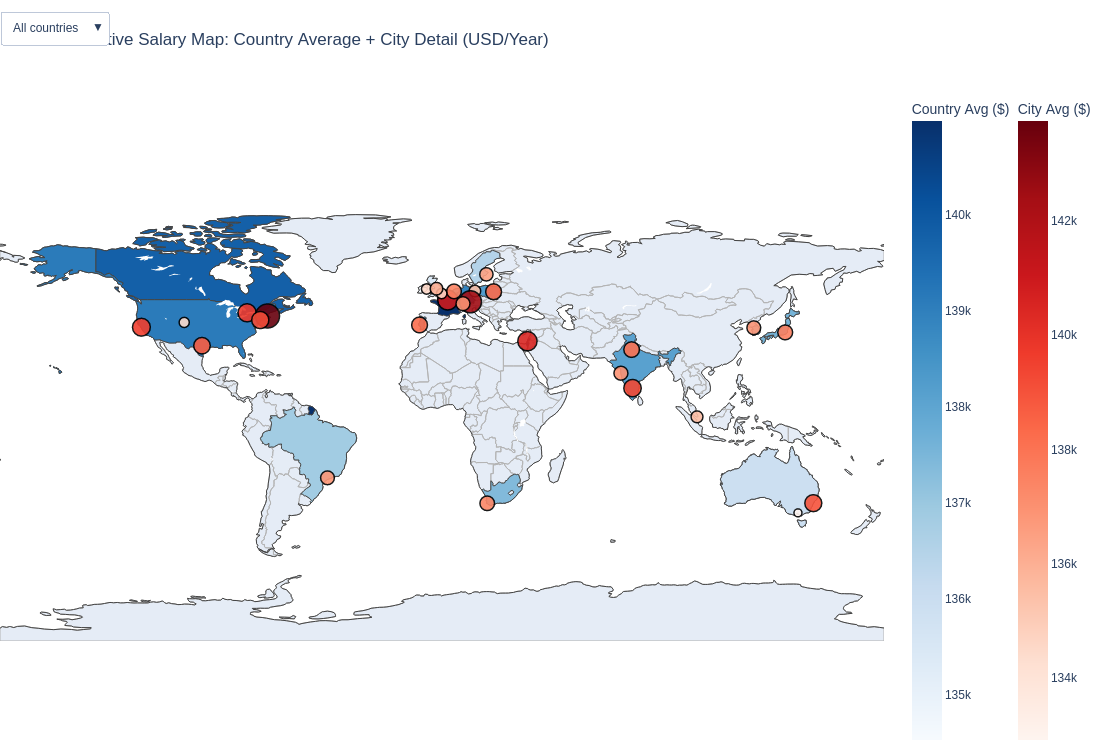

In [7]:
# 1. Aggregate: country level + city level
avg_salary_country = (
    clean.groupby('Country', as_index=False)[SAL].mean().round(2)
    .rename(columns={SAL: 'Country_Avg_Salary'})
)

avg_salary_city = (
    clean.groupby(['Country', 'City'], as_index=False)
    .agg(City_Avg_Salary=(SAL, 'mean'), Postings_Count=(SAL, 'count'))
    .round(2)
)

# 2. Geocode cities (cached, rate-limited)
geolocator = Nominatim(user_agent='salary_map_visualizer')
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1, max_retries=2, error_wait_seconds=3)

cache = {}
def get_coords(city, country):
    key = (city, country)
    if key not in cache:
        try:
            loc = geocode(f'{city}, {country}', timeout=10)
            cache[key] = (loc.latitude, loc.longitude) if loc else (None, None)
        except Exception:
            cache[key] = (None, None)
    return cache[key]

coords = [get_coords(city, country) for city, country in zip(avg_salary_city['City'], avg_salary_city['Country'])]
avg_salary_city['Latitude'] = [p[0] for p in coords]
avg_salary_city['Longitude'] = [p[1] for p in coords]

valid_cities = avg_salary_city.dropna(subset=['Latitude', 'Longitude']).copy()
print(f'Geocoded {len(valid_cities)} / {len(avg_salary_city)} cities.')

# 3. Country hover text lists its cities (ranked by avg salary)
def city_breakdown(g, n=6):
    g = g.sort_values('City_Avg_Salary', ascending=False)
    lines = [f'{i+1}. {r.City}: ${r.City_Avg_Salary:,.0f} ({r.Postings_Count} jobs)'
             for i, r in enumerate(g.head(n).itertuples())]
    if len(g) > n:
        lines.append(f'... +{len(g) - n} more cities')
    return '<br>'.join(lines)

breakdown = (avg_salary_city.groupby('Country')
             .apply(city_breakdown, include_groups=False)
             .rename('City_List').reset_index())
avg_salary_country = avg_salary_country.merge(breakdown, on='Country', how='left')

# 4. Marker sizing (global, so sizes stay consistent when filtering)
min_sal, max_sal = valid_cities['City_Avg_Salary'].min(), valid_cities['City_Avg_Salary'].max()
def size_of(s):
    return 8 + (s - min_sal) / (max_sal - min_sal) * 16 if max_sal > min_sal else 12

valid_cities['Size'] = valid_cities['City_Avg_Salary'].apply(size_of)
valid_cities['Label'] = valid_cities['City'] + ' (' + valid_cities['Country'] + ')'

def city_payload(df_):
    return {
        'lat': [df_['Latitude'].tolist()],
        'lon': [df_['Longitude'].tolist()],
        'text': [df_['Label'].tolist()],
        'customdata': [df_[['City_Avg_Salary', 'Postings_Count']].values.tolist()],
        'marker.size': [df_['Size'].tolist()],
        'marker.color': [df_['City_Avg_Salary'].tolist()],
    }

# 5. Build figure
fig = go.Figure()

fig.add_trace(go.Choropleth(
    locations=avg_salary_country['Country'],
    locationmode='country names',
    z=avg_salary_country['Country_Avg_Salary'],
    customdata=avg_salary_country[['City_List']],
    text=avg_salary_country['Country'],
    colorscale='Blues',
    colorbar=dict(title='Country Avg ($)', x=1.02),
    hovertemplate='<b>%{text}</b><br>Country Avg Salary: $%{z:,.0f}'
                  '<br><br><b>Cities (ranked by avg salary):</b><br>%{customdata[0]}<extra></extra>'
))

fig.add_trace(go.Scattergeo(
    lon=valid_cities['Longitude'],
    lat=valid_cities['Latitude'],
    text=valid_cities['Label'],
    customdata=valid_cities[['City_Avg_Salary', 'Postings_Count']].values,
    mode='markers',
    marker=dict(
        size=valid_cities['Size'],
        color=valid_cities['City_Avg_Salary'],
        cmin=min_sal, cmax=max_sal,
        colorscale='Reds',
        colorbar=dict(title='City Avg ($)', x=1.14),
        showscale=True,
        line=dict(width=1.5, color='black'),
        opacity=0.9
    ),
    hovertemplate='<b>%{text}</b><br>City Avg Salary: $%{customdata[0]:,.0f}'
                  '<br>Open Vacancies: %{customdata[1]}<extra></extra>'
))

# 6. Dropdown: all countries, or zoom into one country and show only its cities
def zoom_range(df_, pad=4):
    lat_min, lat_max = df_['Latitude'].min(), df_['Latitude'].max()
    lon_min, lon_max = df_['Longitude'].min(), df_['Longitude'].max()
    p_lat = max(pad, (lat_max - lat_min) * 0.3)
    p_lon = max(pad, (lon_max - lon_min) * 0.3)
    return ([max(lon_min - p_lon, -180), min(lon_max + p_lon, 180)],
            [max(lat_min - p_lat, -90), min(lat_max + p_lat, 90)])

map_buttons = [dict(
    label='All countries',
    method='update',
    args=[city_payload(valid_cities),
          {'geo.lonaxis.range': [-180, 180], 'geo.lataxis.range': [-90, 90],
           'title': 'Interactive Salary Map: Country Average + City Detail (USD/Year)'}],
)]

for country in sorted(valid_cities['Country'].unique()):
    sub = valid_cities[valid_cities['Country'] == country]
    lon_r, lat_r = zoom_range(sub)
    map_buttons.append(dict(
        label=country,
        method='update',
        args=[city_payload(sub),
              {'geo.lonaxis.range': lon_r, 'geo.lataxis.range': lat_r,
               'title': f'Salary by City - {country} (USD/Year)'}],
    ))

# Apply the data update only to the city trace (index 1)
for btn_ in map_buttons:
    btn_['args'] = [btn_['args'][0], btn_['args'][1], [1]]

fig.update_layout(
    title='Interactive Salary Map: Country Average + City Detail (USD/Year)',
    updatemenus=[dict(
        buttons=map_buttons, direction='down', showactive=True,
        x=0.0, xanchor='left', y=1.12, yanchor='top'
    )],
    geo=dict(
        showframe=False,
        showcoastlines=True,
        showcountries=True,
        countrycolor='rgb(180, 180, 180)',
        projection_type='equirectangular',
        lonaxis=dict(range=[-180, 180]),
        lataxis=dict(range=[-90, 90]),
    ),
    margin=dict(l=0, r=0, t=90, b=0),
    height=750
)

show_fig(fig, 'salary_map')

## 3. Average salary by domain
Horizontal bars, 2024 vs 2025, sorted by overall average (dropdown: both years / 2024 only / 2025 only).

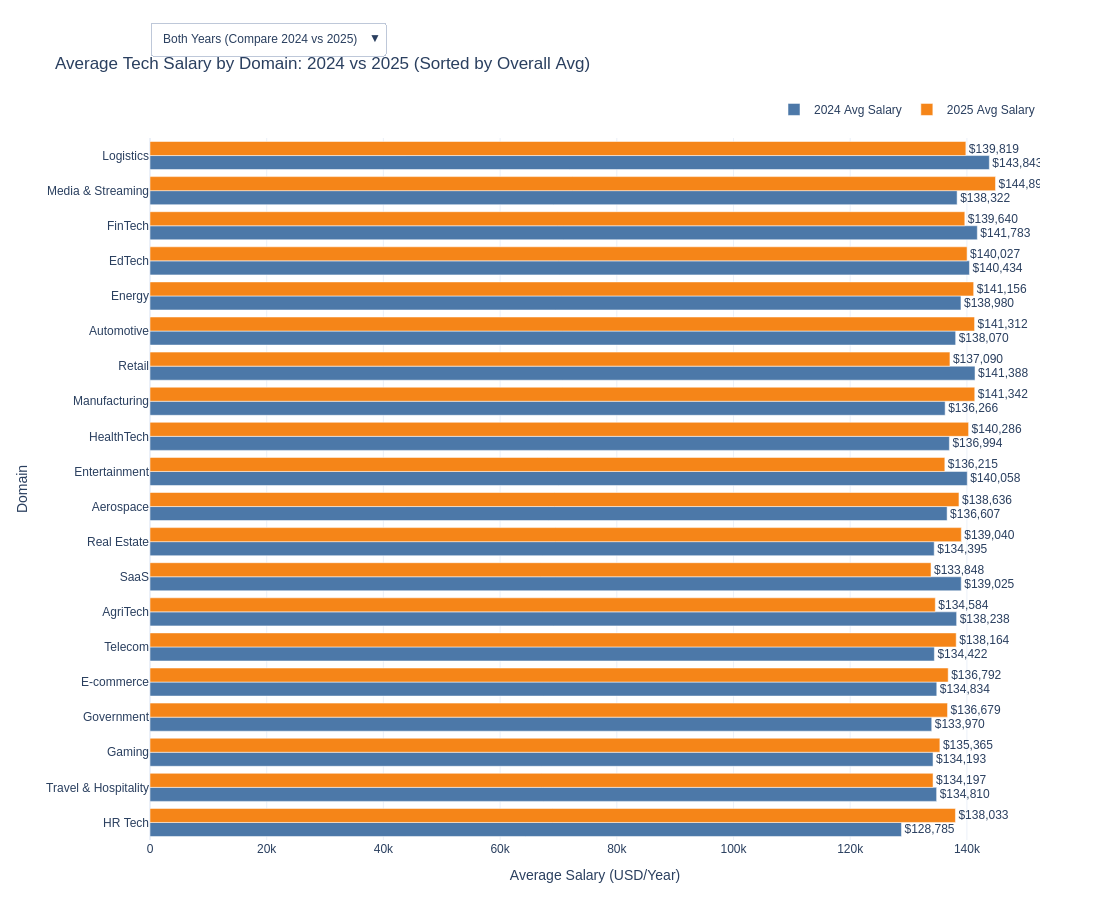

In [8]:
# 1. Clean and prepare data
df_domain = clean.dropna(subset=['Domain', SAL, 'Date Posted']).copy()

# Ensure numeric salary
if df_domain[SAL].dtype == 'object':
    df_domain[SAL] = df_domain[SAL].astype(str).str.replace(r'[$,]', '', regex=True)
df_domain[SAL] = pd.to_numeric(df_domain[SAL], errors='coerce')
df_domain = df_domain.dropna(subset=[SAL])

# Extract and filter years (2024 & 2025)
df_domain['Date Posted'] = pd.to_datetime(df_domain['Date Posted'], errors='coerce')
df_domain['Posting Year'] = df_domain['Date Posted'].dt.year
df_domain = df_domain[df_domain['Posting Year'].isin([2024, 2025])]
df_domain['Posting Year'] = df_domain['Posting Year'].astype(int).astype(str)

# 2. Pivot table: index = Domain, columns = 2024, 2025
domain_pivot = (
    df_domain.groupby(['Domain', 'Posting Year'])[SAL]
    .mean().round(2).unstack(fill_value=0).reset_index()
)
for yr in YEAR_COLORS:
    if yr not in domain_pivot.columns:
        domain_pivot[yr] = 0

# Overall average across both years (used for the combined sort)
domain_pivot['Overall'] = domain_pivot[['2024', '2025']].replace(0, pd.NA).mean(axis=1).fillna(0).round(2)

def get_sorted_data(sort_col):
    """Ascending sort, so the highest value appears on top of a horizontal bar chart."""
    sorted_df = domain_pivot.sort_values(by=sort_col, ascending=True)
    return sorted_df['Domain'].tolist(), sorted_df['2024'].tolist(), sorted_df['2025'].tolist()

def money_labels(values):
    return [f'${v:,.0f}' if v > 0 else 'N/A' for v in values]

d_all, v24_all, v25_all = get_sorted_data('Overall')
d_24, v24_only, _ = get_sorted_data('2024')
d_25, _, v25_only = get_sorted_data('2025')

# 3. Figure with two horizontal traces
fig = go.Figure()
for yr, vals, color in [('2024', v24_all, '#4C78A8'), ('2025', v25_all, '#F58518')]:
    fig.add_trace(go.Bar(
        y=d_all, x=vals, name=f'{yr} Avg Salary', orientation='h', marker_color=color,
        text=money_labels(vals), textposition='outside',
        hovertemplate=f'<b>Domain:</b> %{{y}}<br>{yr} Avg Salary: $%{{x:,.2f}}<extra></extra>'
    ))

# 4. Dropdown (filter + automatic re-sort high -> low)
domain_buttons = [
    dict(label='Both Years (Compare 2024 vs 2025)', method='update', args=[
        {'y': [d_all, d_all], 'x': [v24_all, v25_all],
         'text': [money_labels(v24_all), money_labels(v25_all)], 'visible': [True, True]},
        {'title': 'Average Tech Salary by Domain: 2024 vs 2025 (Sorted by Overall Avg)', 'barmode': 'group'}]),
    dict(label='Only 2024 (Ranked High to Low)', method='update', args=[
        {'y': [d_24, []], 'x': [v24_only, []],
         'text': [money_labels(v24_only), []], 'visible': [True, False]},
        {'title': 'Average Tech Salary by Domain in 2024 (Highest to Lowest)', 'barmode': 'group'}]),
    dict(label='Only 2025 (Ranked High to Low)', method='update', args=[
        {'y': [[], d_25], 'x': [[], v25_only],
         'text': [[], money_labels(v25_only)], 'visible': [False, True]},
        {'title': 'Average Tech Salary by Domain in 2025 (Highest to Lowest)', 'barmode': 'group'}]),
]

# 5. Layout
fig.update_layout(
    updatemenus=[dict(active=0, buttons=domain_buttons, direction='down', pad={'r': 10, 't': 10},
                      showactive=True, x=0.0, xanchor='left', y=1.18, yanchor='top')],
    title='Average Tech Salary by Domain: 2024 vs 2025 (Sorted by Overall Avg)',
    xaxis_title='Average Salary (USD/Year)', yaxis_title='Domain',
    barmode='group', template='plotly_white',
    height=max(550, len(domain_pivot) * 45),
    margin=dict(t=100, b=60, l=150, r=60),
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1)
)

show_fig(fig, 'salary_by_domain')

## 4. Most required skills
### 4.1 Prepare skills data (one row per skill per posting)

In [9]:
TOP_OVERALL = 20   # skills shown in the overall chart
TOP_ROLE = 10      # skills shown per role
TOP_ALL = 15       # skills shown for "All jobs" in the role dropdown

skills_long = df[['Job Role', 'Required Skills', 'Date Posted']].dropna().copy()
skills_long['Date Posted'] = pd.to_datetime(skills_long['Date Posted'], errors='coerce')
skills_long = skills_long.dropna(subset=['Date Posted'])
skills_long['Year'] = skills_long['Date Posted'].dt.year
skills_long = skills_long[skills_long['Year'].isin([2024, 2025])]
skills_long['Year'] = skills_long['Year'].astype(str)
skills_long['Skill'] = skills_long['Required Skills'].astype(str).apply(
    lambda x: [i.strip() for i in x.split('|') if i.strip()])
skills_long = skills_long.explode('Skill')

def make_counts(g):
    """Grouped counts -> columns 2024, 2025, Total, Change (2025 - 2024)."""
    c = g.unstack(fill_value=0)
    for yr in YEAR_COLORS:
        if yr not in c.columns:
            c[yr] = 0
    c = c[['2024', '2025']]
    c['Total'] = c['2024'] + c['2025']
    c['Change'] = c['2025'] - c['2024']
    return c

counts_all = make_counts(skills_long.groupby(['Skill', 'Year']).size())                # skill only
counts_role = make_counts(skills_long.groupby(['Job Role', 'Skill', 'Year']).size())   # role x skill

print('Postings by year:', skills_long.groupby('Year').size().to_dict())

Postings by year: {'2024': 49615, '2025': 50385}


### 4.2 Top skills overall (2024 vs 2025)

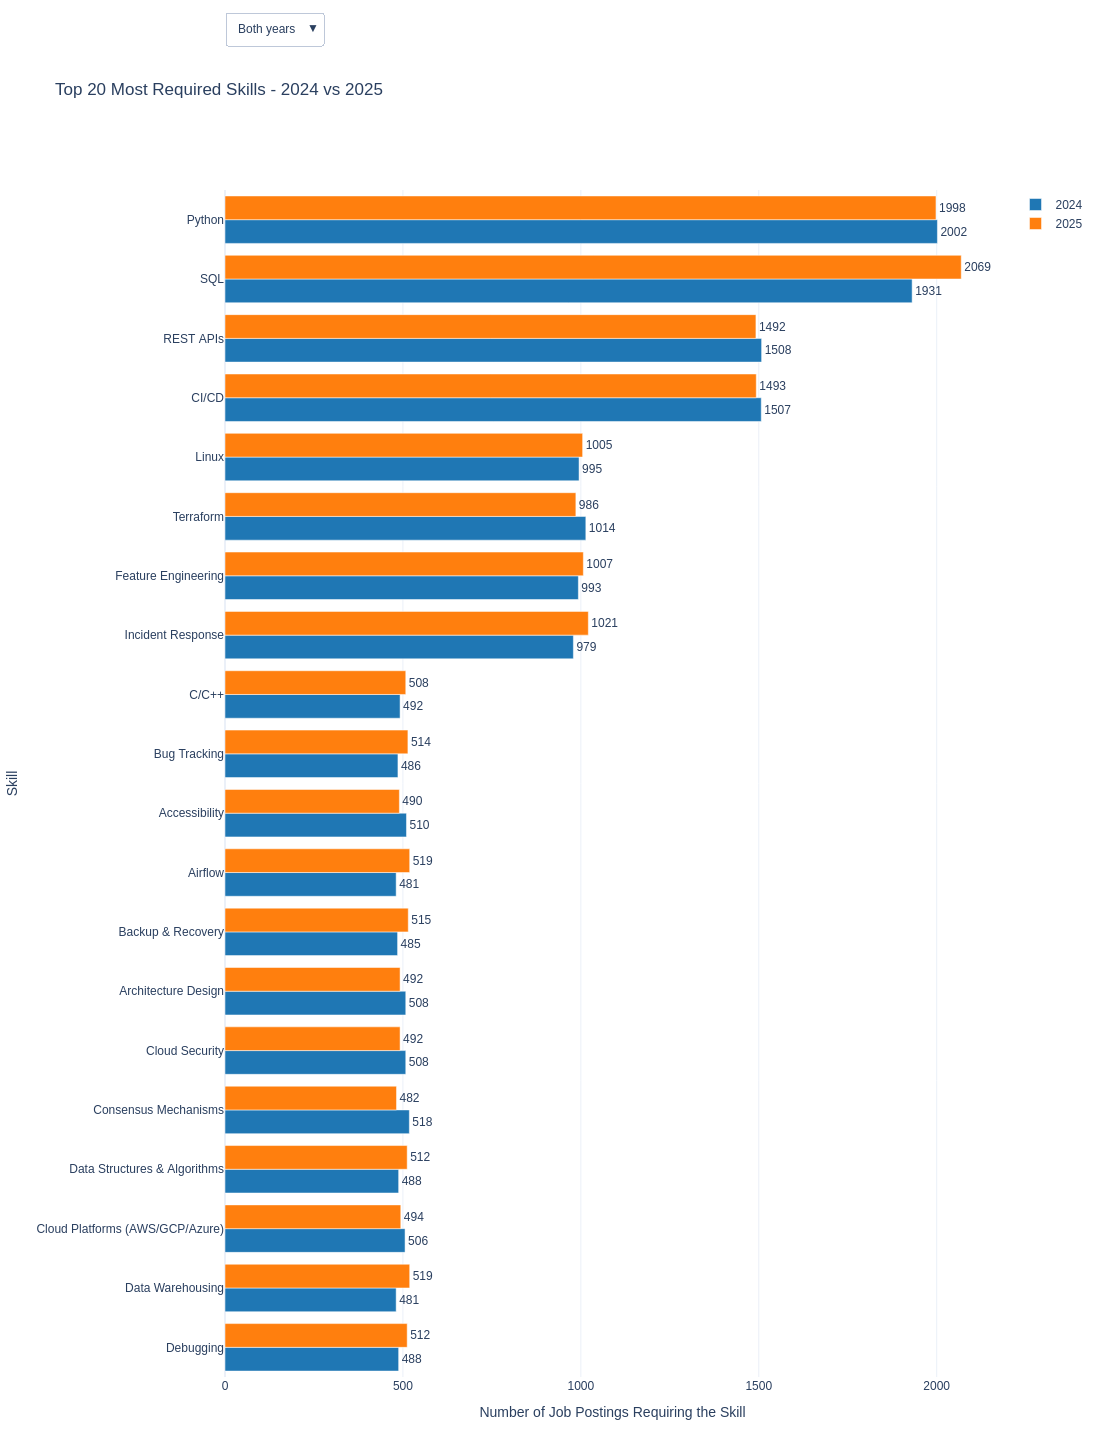

In [10]:
top = counts_all.sort_values('Total', ascending=False).head(TOP_OVERALL)
order_both = top.sort_values('Total').index.tolist()      # bottom -> top
order_24 = top.sort_values('2024').index.tolist()
order_25 = top.sort_values('2025').index.tolist()

fig = go.Figure()
for yr in ['2024', '2025']:
    fig.add_trace(go.Bar(
        y=top.index, x=top[yr], orientation='h', name=yr, marker_color=YEAR_COLORS[yr],
        text=top[yr], textposition='outside', customdata=top['Change'],
        hovertemplate='%{y}<br>' + yr + ': %{x} postings<br>Change 2024→2025: %{customdata:+d}<extra></extra>'))

def skill_btn(label, vis, order, title):
    return dict(label=label, method='update',
                args=[{'visible': vis},
                      {'yaxis.categoryarray': order, 'yaxis.categoryorder': 'array', 'title.text': title}])

fig.update_layout(
    title=f'Top {TOP_OVERALL} Most Required Skills - 2024 vs 2025',
    barmode='group', template='plotly_white',
    xaxis_title='Number of Job Postings Requiring the Skill', yaxis_title='Skill',
    yaxis=dict(categoryorder='array', categoryarray=order_both),
    height=max(500, 150 + 32 * TOP_OVERALL * 2), margin=dict(t=110, b=50, l=40, r=60),
    updatemenus=[dict(
        buttons=[skill_btn('Both years', [True, True], order_both, f'Top {TOP_OVERALL} Most Required Skills - 2024 vs 2025'),
                 skill_btn('2024 only', [True, False], order_24, f'Top {TOP_OVERALL} Most Required Skills - 2024'),
                 skill_btn('2025 only', [False, True], order_25, f'Top {TOP_OVERALL} Most Required Skills - 2025')],
        direction='down', x=0, xanchor='left', y=1.15, yanchor='top', showactive=True)])

show_fig(fig, 'top_skills_overall')

### 4.3 Top skills by job role (dropdown)
Static mode shows the "All jobs" view; use the HTML file in `charts/` for the full dropdown.

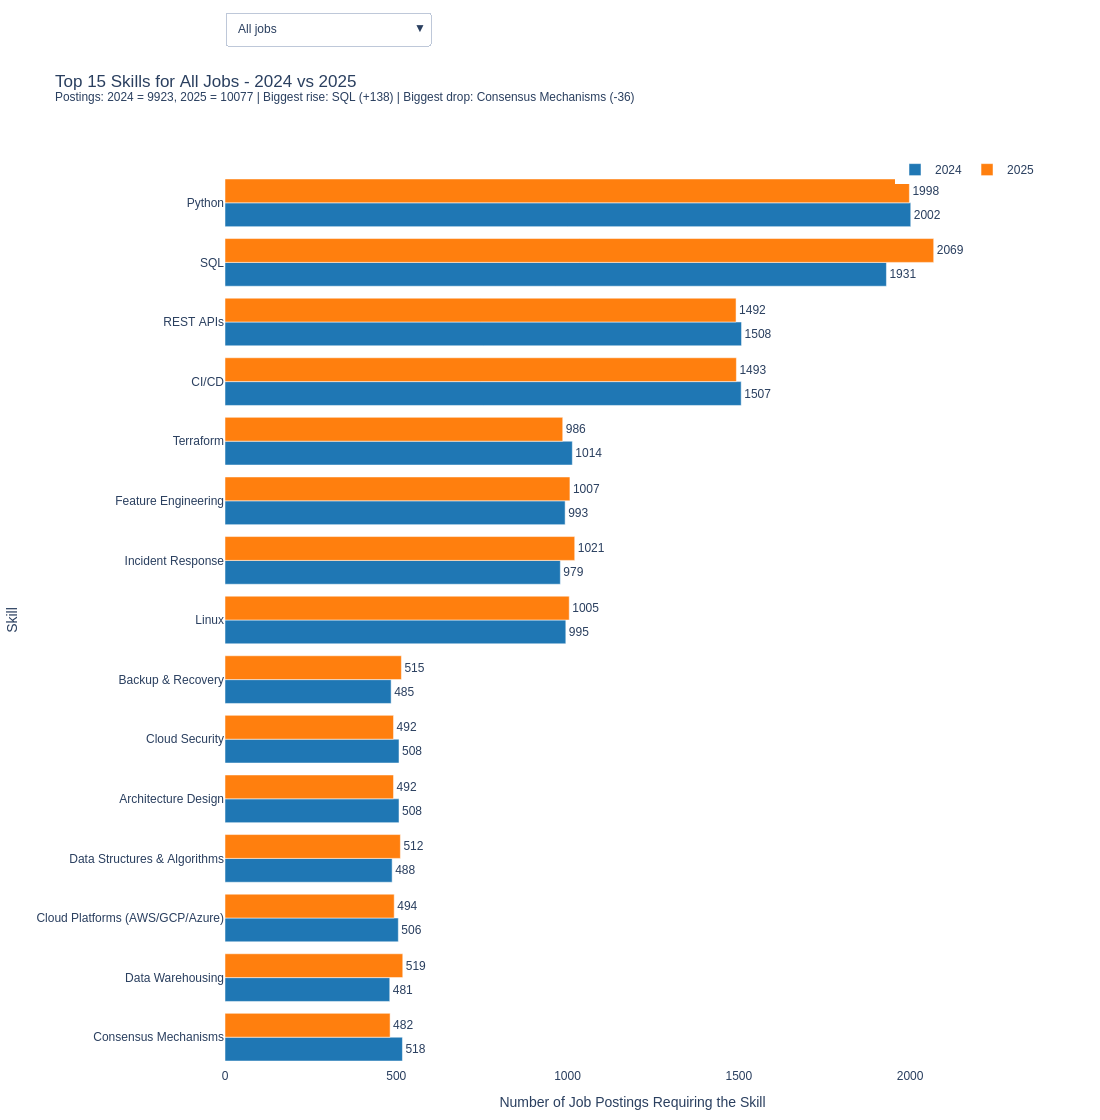

In [11]:
# Postings per role / year (+ overall) for the subtitle
post_df = df.assign(_d=pd.to_datetime(df['Date Posted'], errors='coerce')).dropna(subset=['_d'])
post_df['Year'] = post_df['_d'].dt.year.astype(str)
postings = post_df.groupby(['Job Role', 'Year']).size()
postings_all = post_df.groupby('Year').size()

skill_roles = sorted(counts_role.index.get_level_values('Job Role').unique())
skill_options = [ALL_JOBS] + skill_roles

# Metadata + traces (2 traces per option)
fig = go.Figure()
meta = {}
for i, opt in enumerate(skill_options):
    if opt == ALL_JOBS:
        data, n = counts_all.sort_values('Total', ascending=False).head(TOP_ALL), TOP_ALL
        n24, n25 = int(postings_all.get('2024', 0)), int(postings_all.get('2025', 0))
        label_ = 'All Jobs'
    else:
        data, n = counts_role.loc[opt].sort_values('Total', ascending=False).head(TOP_ROLE), TOP_ROLE
        n24, n25 = int(postings.get((opt, '2024'), 0)), int(postings.get((opt, '2025'), 0))
        label_ = f"'{opt}'"

    order = data.sort_values('Total').index.tolist()                   # bottom -> top
    xmax = max(data[['2024', '2025']].values.max() * 1.15, 1)
    ch = data.sort_values('Change', ascending=False)
    sub = f'Postings: 2024 = {n24}, 2025 = {n25}'
    if len(ch) > 1:
        sub += (f" | Biggest rise: {ch.index[0]} ({ch['Change'].iloc[0]:+d})"
                f" | Biggest drop: {ch.index[-1]} ({ch['Change'].iloc[-1]:+d})")
    meta[opt] = dict(order=order, xmax=xmax,
                     title=f'Top {n} Skills for {label_} - 2024 vs 2025<br><sup>{sub}</sup>')

    for yr in ['2024', '2025']:
        fig.add_trace(go.Bar(
            y=data.index, x=data[yr], orientation='h', name=yr, marker_color=YEAR_COLORS[yr],
            text=data[yr], textposition='outside', customdata=data['Change'],
            visible=(i == 0), legendgroup=yr, showlegend=(i == 0),
            hovertemplate='%{y}<br>' + yr + ': %{x} postings'
                          '<br>Change 2024→2025: %{customdata:+d}<extra></extra>'))

# Dropdown buttons
role_buttons = []
for i, opt in enumerate(skill_options):
    vis = [False] * (2 * len(skill_options))
    vis[2 * i] = vis[2 * i + 1] = True
    role_buttons.append(dict(
        label=opt, method='update',
        args=[{'visible': vis, 'showlegend': vis},
              {'title.text': meta[opt]['title'],
               'yaxis.categoryarray': meta[opt]['order'],
               'xaxis.range': [0, meta[opt]['xmax']]}]))

first = meta[ALL_JOBS]
fig.update_layout(
    title=first['title'], barmode='group', template='plotly_white',
    xaxis=dict(title='Number of Job Postings Requiring the Skill', range=[0, first['xmax']]),
    yaxis=dict(title='Skill', categoryorder='array', categoryarray=first['order']),
    height=max(500, 160 + 32 * max(TOP_ROLE, TOP_ALL) * 2), margin=dict(t=130, b=50, l=40, r=60),
    legend=dict(orientation='h', y=1.02, x=1, xanchor='right'),
    updatemenus=[dict(buttons=role_buttons, direction='down', x=0, xanchor='left',
                      y=1.18, yanchor='top', showactive=True)])

show_fig(fig, 'top_skills_by_role')

## 5. Job vacancies by role
Static mode: all jobs, 2024 vs 2025. Interactive mode: year buttons + job-role dropdown.

Roles: 20 | Postings: 20000


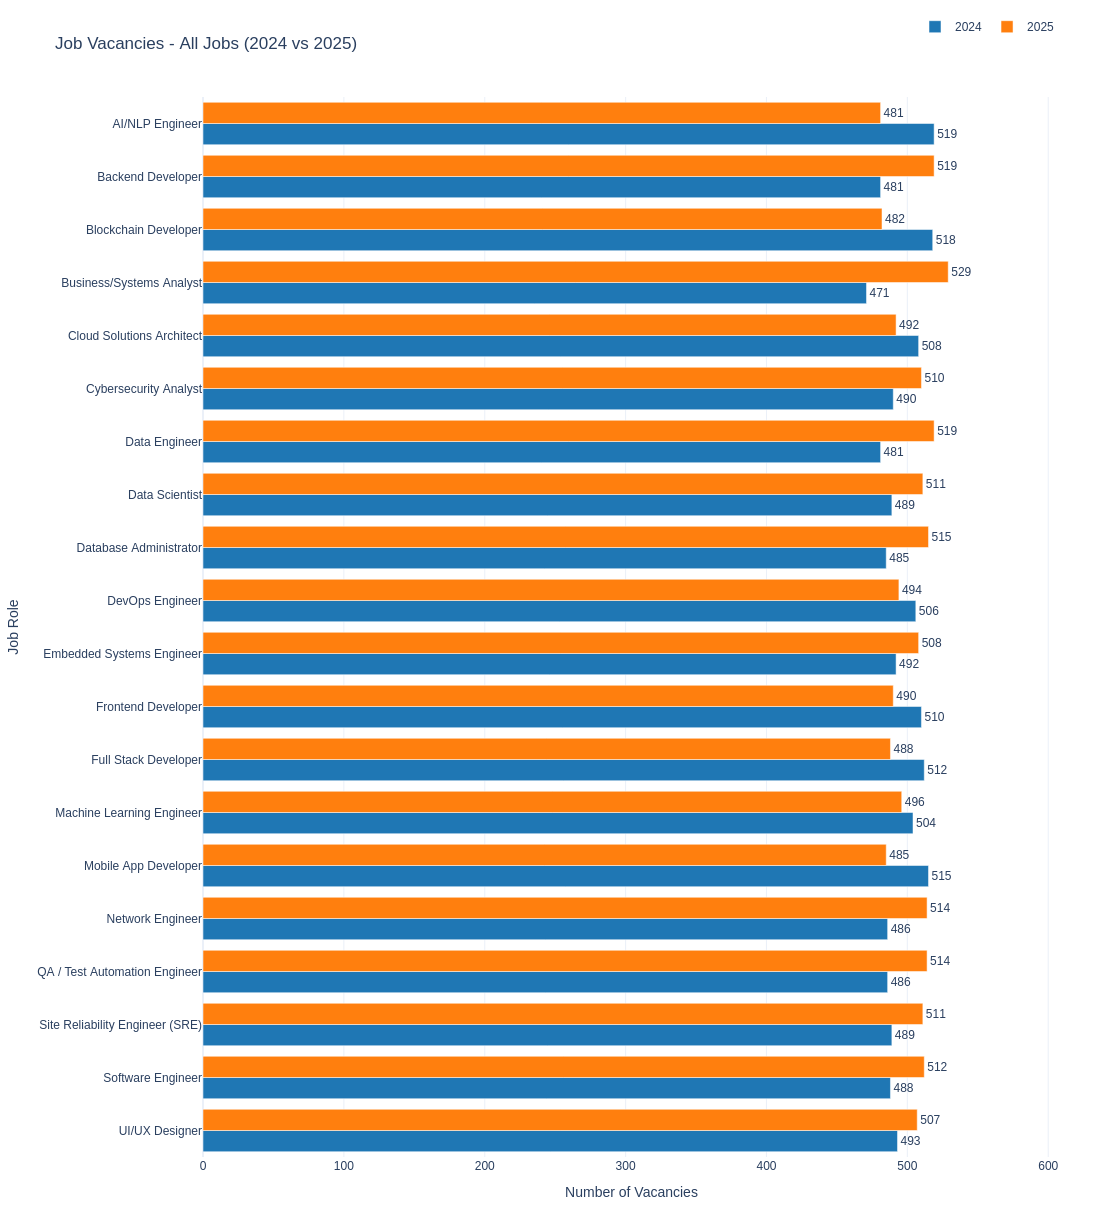

In [12]:
YEARS_BOTH = 'Both years (2024 vs 2025)'

# 1. Clean & prepare data
df_trend = clean.dropna(subset=['Date Posted', 'Job Role']).copy()
df_trend['Job Role'] = df_trend['Job Role'].astype(str).str.strip()
df_trend = df_trend[df_trend['Job Role'] != '']
df_trend['Date Posted'] = pd.to_datetime(df_trend['Date Posted'], errors='coerce')
df_trend = df_trend.dropna(subset=['Date Posted'])
df_trend['Posting Year'] = df_trend['Date Posted'].dt.year
df_trend = df_trend[df_trend['Posting Year'].isin([2024, 2025])]
df_trend['Posting Year'] = df_trend['Posting Year'].astype(int).astype(str)

# 2. Pivot: index = Job Role, columns = 2024 / 2025
vacancies = df_trend.groupby(['Job Role', 'Posting Year']).size().unstack(fill_value=0)
for yr in YEAR_COLORS:
    if yr not in vacancies.columns:
        vacancies[yr] = 0
vacancies = vacancies[['2024', '2025']]
vacancies['Total'] = vacancies['2024'] + vacancies['2025']
print('Roles:', len(vacancies), '| Postings:', int(vacancies['Total'].sum()))

# 3. Figure builder
def vacancy_fig(year, role):
    data = vacancies if role == ALL_JOBS else vacancies.loc[[role]]
    years = ['2024', '2025'] if year == YEARS_BOTH else [year]

    # sort by count, ties broken by role name (stable, never errors)
    sort_col = 'Total' if len(years) == 2 else years[0]
    data = (data.assign(_name=data.index.astype(str).str.lower())
                .sort_values([sort_col, '_name'], ascending=[True, False])
                .drop(columns='_name'))

    fig = go.Figure()
    for yr in years:
        fig.add_trace(go.Bar(
            y=data.index, x=data[yr], orientation='h', name=yr, marker_color=YEAR_COLORS[yr],
            text=data[yr], textposition='outside',
            hovertemplate='%{y}<br>' + yr + ': %{x} vacancies<extra></extra>'))

    yr_label = '2024 vs 2025' if len(years) == 2 else years[0]
    job_label = 'All Jobs' if role == ALL_JOBS else role
    title = f'Job Vacancies - {job_label} ({yr_label})'
    if role != ALL_JOBS and len(years) == 2:
        v24, v25 = int(data['2024'].iloc[0]), int(data['2025'].iloc[0])
        if v24 == v25:
            title += f'<br><sup>Same demand in both years ({v24})</sup>'
        else:
            hi, diff = ('2025', v25 - v24) if v25 > v24 else ('2024', v24 - v25)
            title += f'<br><sup>{hi} has {diff} more vacancies</sup>'

    max_val = data[years].values.max()
    fig.update_layout(
        title=title, barmode='group', template='plotly_white',
        xaxis_title='Number of Vacancies', yaxis_title='Job Role',
        height=max(350, 90 + 28 * len(data) * len(years)),
        margin=dict(t=90, b=50, l=40, r=40),
        legend=dict(orientation='h', y=1.08, x=1, xanchor='right'))
    fig.update_xaxes(range=[0, max(max_val * 1.15, 1)])
    return fig

# 4. Show
if STATIC_MODE:
    show_fig(vacancy_fig(YEARS_BOTH, ALL_JOBS), 'job_vacancies_all_jobs')
else:
    def draw_vacancies(year, role):
        try:
            show_fig(vacancy_fig(year, role), 'job_vacancies_interactive', save_html=False)
        except Exception:
            print(traceback.format_exc())

    w_year = widgets.ToggleButtons(options=[YEARS_BOTH, '2024', '2025'], value=YEARS_BOTH,
                                   description='Year:', button_style='info')
    w_role = widgets.Dropdown(options=[ALL_JOBS] + sorted(vacancies.index.tolist(), key=lambda s: s.lower()),
                              value=ALL_JOBS, description='Job Role:',
                              layout=widgets.Layout(width='350px'))
    out_vac = widgets.interactive_output(draw_vacancies, {'year': w_year, 'role': w_role})
    display(widgets.VBox([w_year, w_role]), out_vac)

## 6. Average salary by role x level
Static mode: heatmap for all years + the 2024 -> 2025 change. Interactive mode: year buttons + role dropdown.

Level order used: ['Junior', 'Mid-Level', 'Senior', 'Lead', 'Principal / Staff']
Years found: [2024, 2025] | Roles: 20


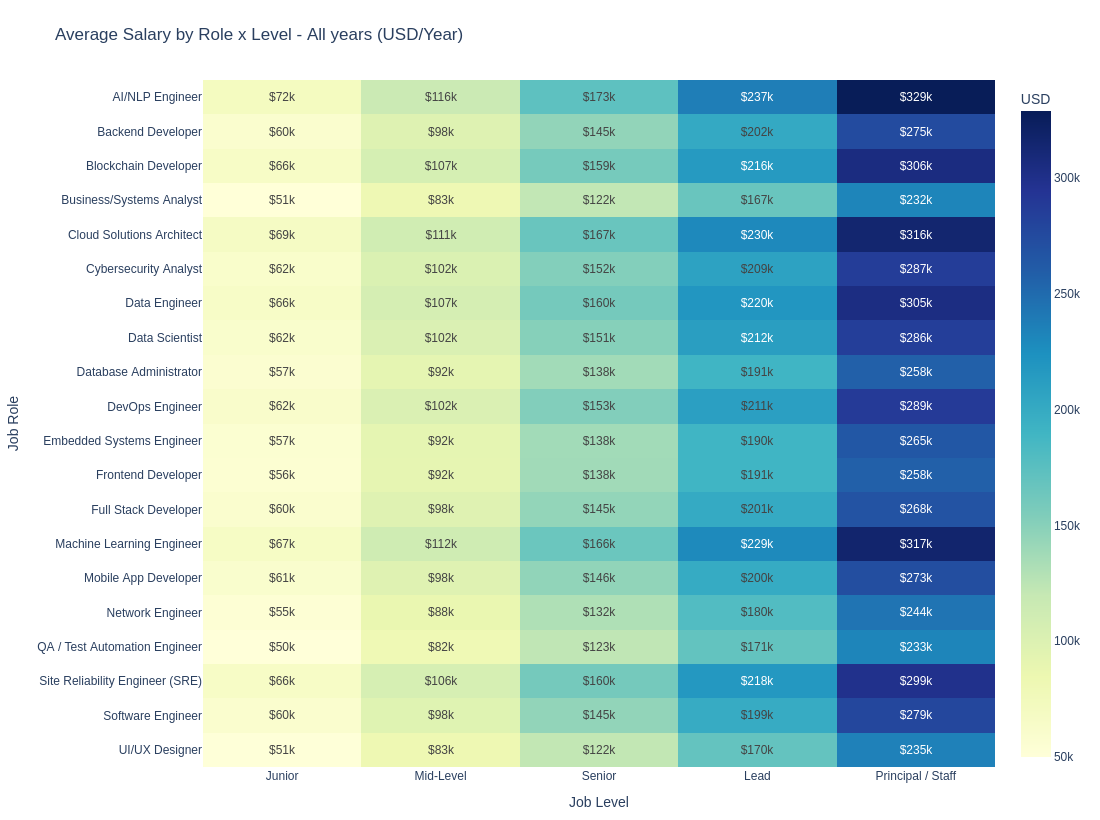

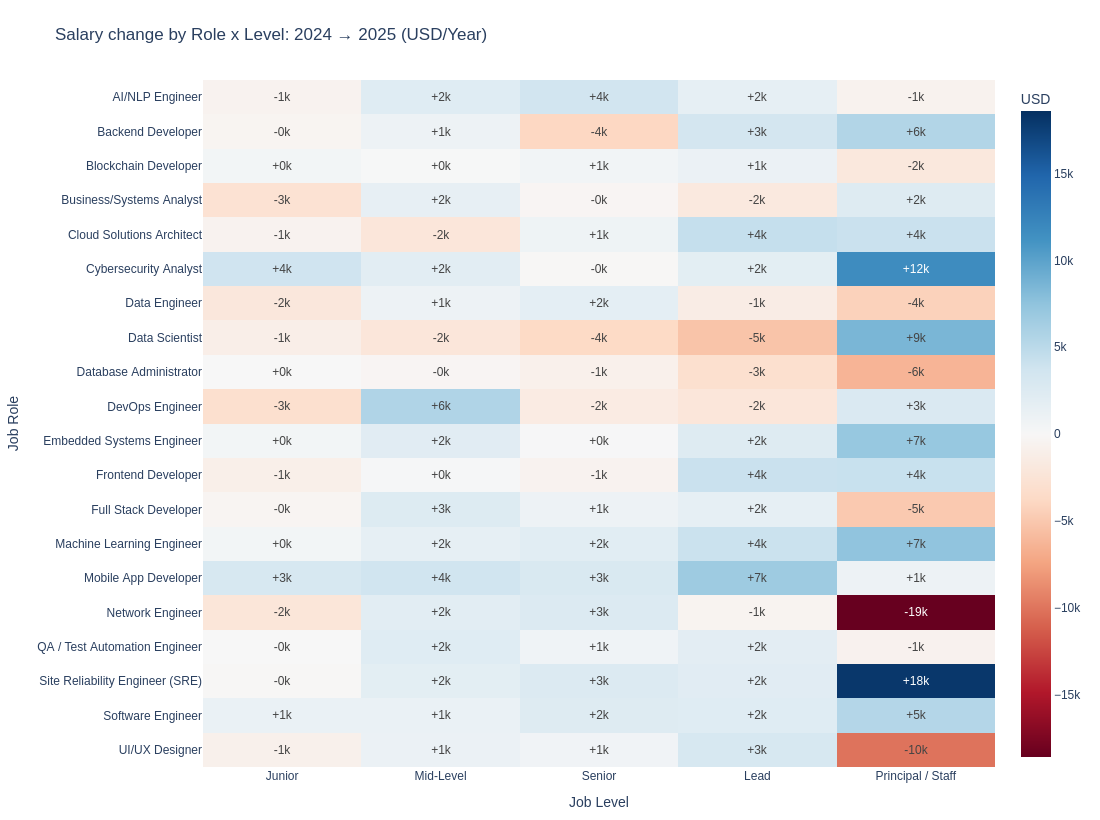

In [13]:
# 1. Prepare data
rl = df[['Job Role', 'Job Level', SAL, 'Date Posted']].copy()
rl[SAL] = pd.to_numeric(rl[SAL], errors='coerce')
rl['Date Posted'] = pd.to_datetime(rl['Date Posted'], errors='coerce')
rl = rl.dropna(subset=['Job Role', 'Job Level', SAL])

rl['Job Role'] = rl['Job Role'].astype(str).str.strip()
rl['Job Level'] = rl['Job Level'].astype(str).str.strip()
rl = rl[(rl['Job Role'] != '') & (rl['Job Level'] != '')]
rl['Year'] = rl['Date Posted'].dt.year.fillna(0).astype(int)   # 0 = unknown date

rl_years = sorted(int(y) for y in rl['Year'].unique() if y > 0)
rl_roles = sorted(rl['Job Role'].unique(), key=lambda s: s.lower())
rl_levels = order_levels(rl['Job Level'].unique())
print('Level order used:', rl_levels)
print('Years found:', rl_years, '| Roles:', len(rl_roles))

ALL_ROLES, YEARS_ALL, COMPARE = 'All roles', 'All years', 'Compare years'
PALETTE = px.colors.qualitative.Plotly

def role_level_pivot(data, how):
    return (data.pivot_table(index='Job Role', columns='Job Level', values=SAL, aggfunc=how)
                .reindex(index=rl_roles, columns=rl_levels))

def fmt_k(v, sign=False):
    if pd.isna(v):
        return ''
    return f'{v/1000:+,.0f}k' if sign else f'${v/1000:,.0f}k'

# 2. Figure builder
def role_level_fig(role, year):
    # All roles -> heatmap Role x Level
    if role == ALL_ROLES:
        if year == COMPARE and len(rl_years) >= 2:
            y0, y1 = rl_years[0], rl_years[-1]
            z = role_level_pivot(rl[rl.Year == y1], 'mean') - role_level_pivot(rl[rl.Year == y0], 'mean')
            n = role_level_pivot(rl[rl.Year.isin([y0, y1])], 'count').fillna(0)
            title = f'Salary change by Role x Level: {y0} → {y1} (USD/Year)'
            text = [[fmt_k(v, True) for v in r] for r in z.values]
            scale, zmid = 'RdBu', 0
        else:
            data = rl if year in (YEARS_ALL, COMPARE) else rl[rl.Year == int(year)]
            z, n = role_level_pivot(data, 'mean'), role_level_pivot(data, 'count').fillna(0)
            label_ = 'All years' if year in (YEARS_ALL, COMPARE) else year
            title = f'Average Salary by Role x Level - {label_} (USD/Year)'
            text = [[fmt_k(v) for v in r] for r in z.values]
            scale, zmid = 'YlGnBu', None

        fig = go.Figure(go.Heatmap(
            z=z.values, x=rl_levels, y=rl_roles, customdata=n.values,
            text=text, texttemplate='%{text}', colorscale=scale, zmid=zmid,
            colorbar=dict(title='USD'),
            hovertemplate='%{y} | %{x}<br>Value: %{z:,.0f}<br>Postings: %{customdata:.0f}<extra></extra>'))
        fig.update_layout(title=title, template='plotly_white',
                          height=max(450, 120 + 35 * len(rl_roles)),
                          xaxis_title='Job Level', yaxis_title='Job Role',
                          yaxis=dict(autorange='reversed'),
                          margin=dict(t=80, b=50, l=40, r=40))
        return fig

    # One role -> horizontal bars per level
    sub = rl[rl['Job Role'] == role]
    if year == COMPARE:
        series, label_ = {str(y): sub[sub.Year == y] for y in rl_years}, 'by year'
    elif year == YEARS_ALL:
        series, label_ = {'All years': sub}, 'All years'
    else:
        series, label_ = {year: sub[sub.Year == int(year)]}, year

    fig = go.Figure()
    max_v = 1
    for i, (name, s) in enumerate(series.items()):
        g = s.groupby('Job Level')[SAL].agg(['mean', 'count']).reindex(rl_levels)
        if g['mean'].notna().any():
            max_v = max(max_v, g['mean'].max())
        fig.add_trace(go.Bar(
            y=rl_levels, x=g['mean'], orientation='h', name=name,
            marker_color=PALETTE[i % len(PALETTE)],
            text=[fmt_k(v) for v in g['mean']], textposition='outside',
            customdata=g['count'].fillna(0),
            hovertemplate='%{y}<br>Avg: $%{x:,.0f}<br>Postings: %{customdata:.0f}<extra></extra>'))
    fig.update_layout(
        title=f'Average Salary by Job Level - {role} ({label_})',
        barmode='group', template='plotly_white',
        xaxis_title='Average Salary (USD/Year)', yaxis_title='Job Level',
        yaxis=dict(autorange='reversed'),
        height=max(400, 120 + 40 * len(rl_levels) * len(series)),
        margin=dict(t=80, b=50, l=40, r=60),
        legend=dict(orientation='h', y=1.08, x=1, xanchor='right'))
    fig.update_xaxes(range=[0, max_v * 1.2])
    return fig

# 3. Show
if STATIC_MODE:
    show_fig(role_level_fig(ALL_ROLES, YEARS_ALL), 'salary_role_level_all_years')
    if len(rl_years) >= 2:
        show_fig(role_level_fig(ALL_ROLES, COMPARE), 'salary_role_level_change')
else:
    w_year_rl = widgets.ToggleButtons(options=[YEARS_ALL] + [str(y) for y in rl_years] + [COMPARE],
                                      value=YEARS_ALL, description='Year:', button_style='info')
    w_role_rl = widgets.Dropdown(options=[ALL_ROLES] + rl_roles, value=ALL_ROLES, description='Job Role:',
                                 layout=widgets.Layout(width='400px'))
    chart_box = widgets.VBox()
    err_box = widgets.Output()   # callback errors are printed here instead of being hidden

    def update_role_level(_=None):
        err_box.clear_output()
        try:
            chart_box.children = [go.FigureWidget(role_level_fig(w_role_rl.value, w_year_rl.value))]
        except Exception:
            with err_box:
                print(traceback.format_exc())

    w_year_rl.observe(update_role_level, names='value')
    w_role_rl.observe(update_role_level, names='value')
    update_role_level()
    display(widgets.VBox([w_year_rl, w_role_rl, chart_box, err_box]))

## 7. What drives salary? (experience / level / role)

In [14]:
sal_df = df[['Job Role', 'Job Level', EXP, SAL]].copy()
sal_df[SAL] = pd.to_numeric(sal_df[SAL], errors='coerce')
sal_df[EXP] = pd.to_numeric(sal_df[EXP], errors='coerce')
sal_df = sal_df.dropna()

# Ordinal-encode Job Level (junior -> senior)
sal_levels = order_levels(sal_df['Job Level'].unique())
sal_df['Level_Code'] = sal_df['Job Level'].map({l: i for i, l in enumerate(sal_levels)})
print('Level order (0 = lowest):', sal_levels)

# Correlation ratio (eta): strength of a categorical variable vs a numeric one
def eta(cat, y):
    grand = y.mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for _, g in y.groupby(cat))
    ss_total = ((y - grand) ** 2).sum()
    return float(np.sqrt(ss_between / ss_total)) if ss_total > 0 else np.nan

def strength(v):
    v = abs(v)
    return 'negligible' if v < 0.1 else 'weak' if v < 0.3 else 'moderate' if v < 0.5 else 'strong'

# 1. Numbers
pr, pr_p = stats.pearsonr(sal_df[EXP], sal_df[SAL])
sr, sr_p = stats.spearmanr(sal_df[EXP], sal_df[SAL])
lr, lr_p = stats.spearmanr(sal_df['Level_Code'], sal_df[SAL])
el_lr, el_p = stats.spearmanr(sal_df[EXP], sal_df['Level_Code'])
eta_role = eta(sal_df['Job Role'], sal_df[SAL])
eta_level = eta(sal_df['Job Level'], sal_df[SAL])
anova_role = stats.f_oneway(*[g.values for _, g in sal_df.groupby('Job Role')[SAL]])
anova_level = stats.f_oneway(*[g.values for _, g in sal_df.groupby('Job Level')[SAL]])

corr_summary = pd.DataFrame([
    ['Experience (Years)', 'Pearson r', pr, pr ** 2, pr_p],
    ['Experience (Years)', 'Spearman rho', sr, sr ** 2, sr_p],
    ['Job Level (ordinal)', 'Spearman rho', lr, lr ** 2, lr_p],
    ['Job Level (categorical)', 'Eta (ANOVA)', eta_level, eta_level ** 2, anova_level.pvalue],
    ['Job Role (categorical)', 'Eta (ANOVA)', eta_role, eta_role ** 2, anova_role.pvalue],
], columns=['Factor', 'Method', 'Coefficient', 'Variance explained', 'p-value'])
corr_summary['Strength'] = corr_summary['Coefficient'].apply(strength)
corr_summary['Significant (p<0.05)'] = corr_summary['p-value'] < 0.05
display(corr_summary.round(4))
print(f'Experience vs Job Level overlap (Spearman): {el_lr:.3f} ({strength(el_lr)})')

Level order (0 = lowest): ['Junior', 'Mid-Level', 'Senior', 'Lead', 'Principal / Staff']


,Factor,Method,Coefficient,Variance explained,p-value,Strength,Significant (p<0.05)
0,Experience (Years),Pearson r,0.9011,0.8119,0.0,strong,True
1,Experience (Years),Spearman rho,0.9222,0.8504,0.0,strong,True
2,Job Level (ordinal),Spearman rho,0.9491,0.9009,0.0,strong,True
3,Job Level (categorical),Eta (ANOVA),0.9350,0.8742,0.0,strong,True
4,Job Role (categorical),Eta (ANOVA),0.2023,0.0409,0.0,weak,True


Experience vs Job Level overlap (Spearman): 0.973 (strong)


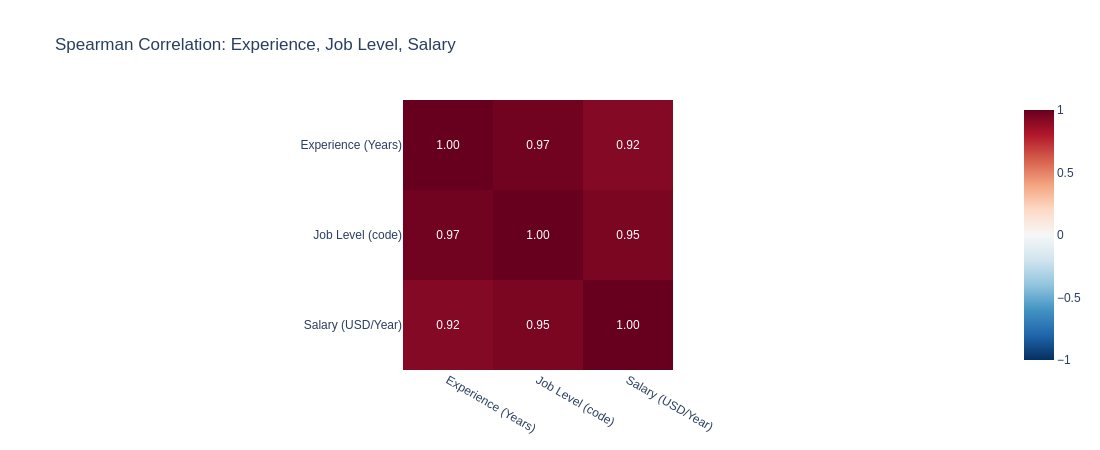

In [15]:
# 2. Correlation heatmap (numeric / ordinal variables)
corr = (sal_df[[EXP, 'Level_Code', SAL]]
        .rename(columns={'Level_Code': 'Job Level (code)'}).corr(method='spearman'))
fig = px.imshow(corr, text_auto='.2f', color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
                title='Spearman Correlation: Experience, Job Level, Salary')
fig.update_layout(height=450, template='plotly_white')
show_fig(fig, 'drivers_correlation_heatmap')

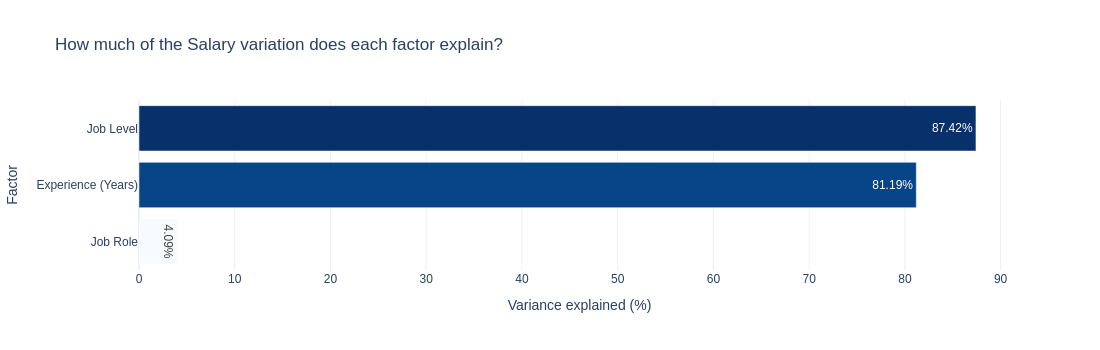

In [16]:
# 3. Which factor explains salary the most? (variance explained)
var_df = pd.DataFrame({
    'Factor': ['Experience (Years)', 'Job Level', 'Job Role'],
    'Variance explained (%)': [pr ** 2 * 100, eta_level ** 2 * 100, eta_role ** 2 * 100],
}).sort_values('Variance explained (%)')
fig = px.bar(var_df, x='Variance explained (%)', y='Factor', orientation='h',
             text=var_df['Variance explained (%)'].round(2).astype(str) + '%',
             title='How much of the Salary variation does each factor explain?',
             color='Variance explained (%)', color_continuous_scale='Blues')
fig.update_layout(template='plotly_white', height=350, coloraxis_showscale=False)
show_fig(fig, 'drivers_variance_explained')

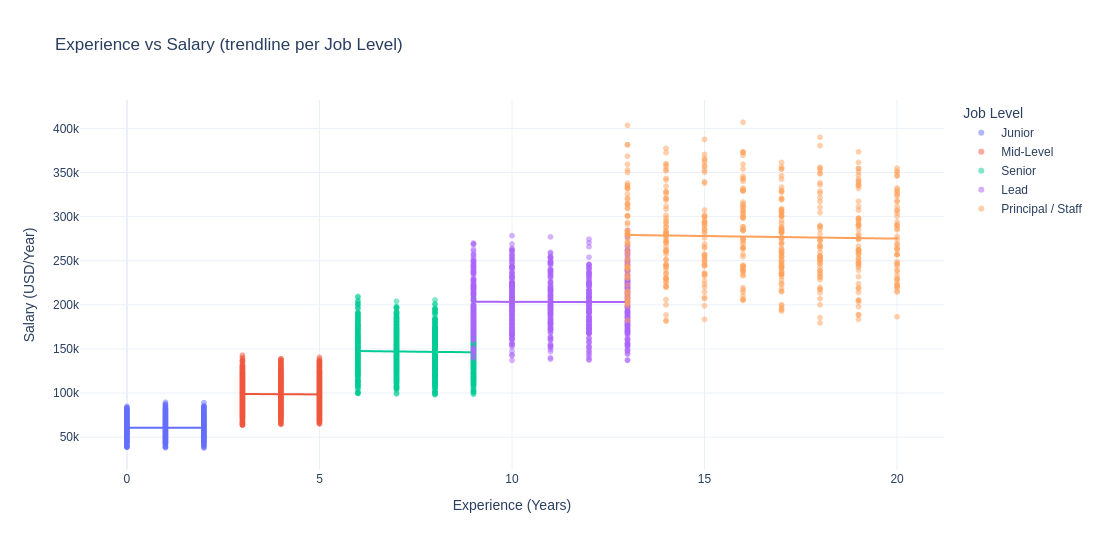

In [17]:
# 4. Scatter: Experience vs Salary, colored by Job Level
plot_df = sal_df.sample(min(len(sal_df), 5000), random_state=42)
fig = px.scatter(plot_df, x=EXP, y=SAL, color='Job Level', opacity=0.5,
                 category_orders={'Job Level': sal_levels}, trendline='ols',
                 hover_data=['Job Role'],
                 title='Experience vs Salary (trendline per Job Level)')
fig.update_layout(template='plotly_white', height=550)
show_fig(fig, 'drivers_experience_vs_salary')

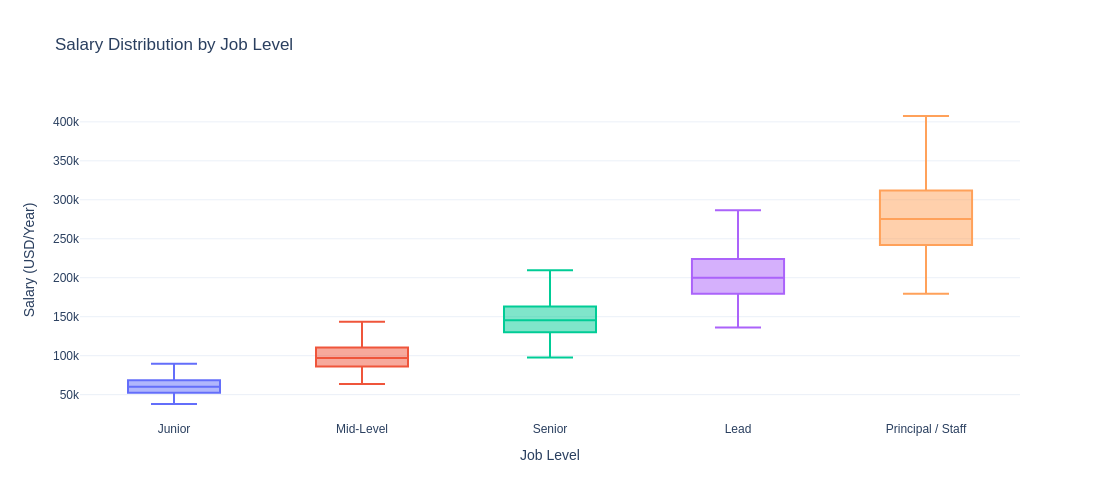

In [18]:
# 5. Salary distribution by Job Level
fig = px.box(sal_df, x='Job Level', y=SAL, color='Job Level', category_orders={'Job Level': sal_levels},
             title='Salary Distribution by Job Level')
fig.update_layout(template='plotly_white', height=500, showlegend=False)
show_fig(fig, 'drivers_salary_by_level')

## 8. Open-door jobs (no certification / no experience / self-taught accepted)
### 8.1 Flag each posting

In [19]:
jobs = clean.copy()
jobs[EXP] = pd.to_numeric(jobs[EXP], errors='coerce')
jobs = jobs.dropna(subset=[EXP])

jobs['No_Cert'] = no_cert(jobs[CERT])
jobs['No_Exp'] = jobs[EXP] == 0
jobs['Self_Taught'] = jobs[EDU].astype(str).str.strip().str.lower() == SELF.lower()

FLAGS = {'No_Cert': 'No cert', 'No_Exp': 'No exp', 'Self_Taught': 'Self-taught OK'}
ALL_REQ = 'All required (cert + exp + formal edu)'

def requirement_label(r):
    parts = [txt for col, txt in FLAGS.items() if r[col]]
    return ' + '.join(parts) if parts else ALL_REQ

jobs['Requirement Group'] = jobs.apply(requirement_label, axis=1)
jobs['Flags'] = jobs[list(FLAGS)].sum(axis=1)
GROUP_ORDER = (jobs.groupby('Requirement Group')['Flags'].first()
                   .sort_values(ascending=False, kind='stable').index.tolist())
n_jobs = len(jobs)

### 8.2 How many jobs do NOT require each item?

,Condition,Jobs,Share (%)
0,No cert,5002,25.0
1,No exp,1346,6.7
2,Self-taught OK,3425,17.1
3,At least one of the 3,8460,42.3
4,At least two of the 3,1265,6.3
5,All 3 (fully open-door),48,0.2
6,None (everything required),11540,57.7


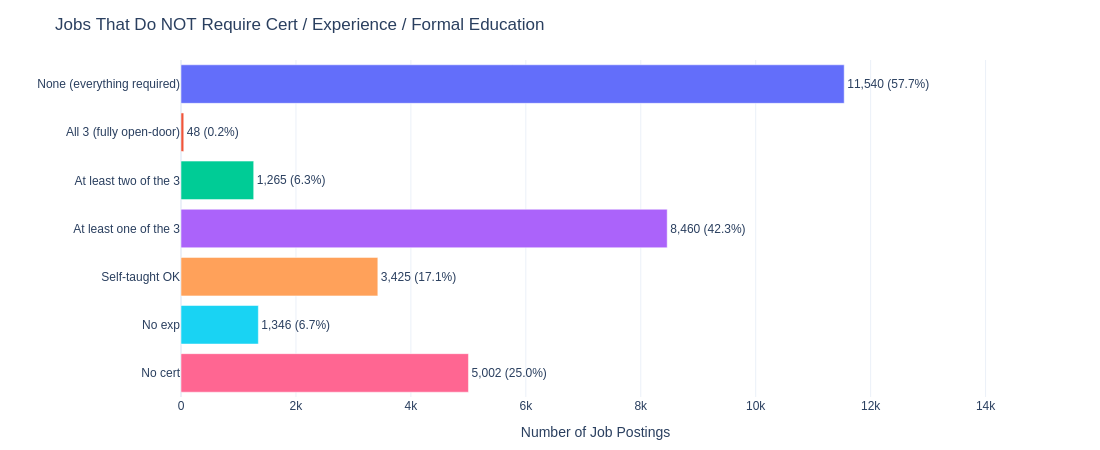

In [20]:
rows = [[txt, int(jobs[col].sum()), jobs[col].mean() * 100] for col, txt in FLAGS.items()]
rows.append(['At least one of the 3', int((jobs.Flags >= 1).sum()), (jobs.Flags >= 1).mean() * 100])
rows.append(['At least two of the 3', int((jobs.Flags >= 2).sum()), (jobs.Flags >= 2).mean() * 100])
rows.append(['All 3 (fully open-door)', int((jobs.Flags == 3).sum()), (jobs.Flags == 3).mean() * 100])
rows.append(['None (everything required)', int((jobs.Flags == 0).sum()), (jobs.Flags == 0).mean() * 100])
open_summary = pd.DataFrame(rows, columns=['Condition', 'Jobs', 'Share (%)']).round({'Share (%)': 1})
display(open_summary)

fig = px.bar(open_summary.iloc[::-1], x='Jobs', y='Condition', orientation='h', color='Condition',
             text=open_summary.iloc[::-1].apply(lambda r: f"{r.Jobs:,} ({r['Share (%)']}%)", axis=1),
             title='Jobs That Do NOT Require Cert / Experience / Formal Education')
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', showlegend=False, height=450, yaxis_title='',
                  xaxis_title='Number of Job Postings', margin=dict(l=40, r=90, t=60, b=40))
fig.update_xaxes(range=[0, open_summary['Jobs'].max() * 1.25])
show_fig(fig, 'open_door_summary')

### 8.3 Every requirement combination

,Requirement Group,Jobs,Share (%)
0,No cert + No exp + Self-taught OK,48,0.2
1,No cert + No exp,241,1.2
2,No cert + Self-taught OK,815,4.1
3,No exp + Self-taught OK,161,0.8
4,No cert,3898,19.5
5,No exp,896,4.5
6,Self-taught OK,2401,12.0
7,All required (cert + exp + formal edu),11540,57.7


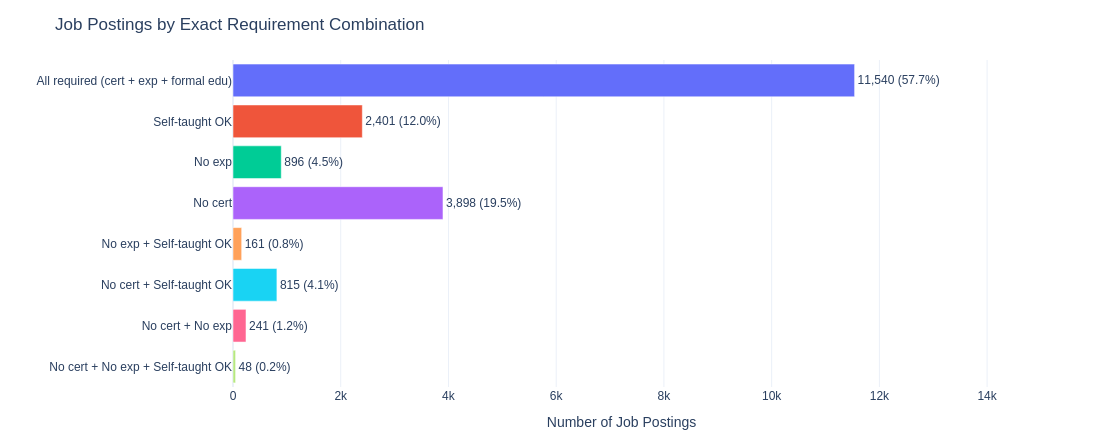

In [21]:
combo = (jobs['Requirement Group'].value_counts().reindex(GROUP_ORDER).rename_axis('Requirement Group')
             .reset_index(name='Jobs'))
combo['Share (%)'] = (combo['Jobs'] / n_jobs * 100).round(1)
display(combo)

fig = px.bar(combo.iloc[::-1], x='Jobs', y='Requirement Group', orientation='h', color='Requirement Group',
             text=combo.iloc[::-1].apply(lambda r: f"{r.Jobs:,} ({r['Share (%)']}%)", axis=1),
             title='Job Postings by Exact Requirement Combination')
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', showlegend=False, yaxis_title='', xaxis_title='Number of Job Postings',
                  height=max(400, 80 + 45 * len(combo)), margin=dict(l=40, r=90, t=60, b=40))
fig.update_xaxes(range=[0, combo['Jobs'].max() * 1.25])
show_fig(fig, 'open_door_combinations')

### 8.4 By job role / job level (% of postings that don't require each item)

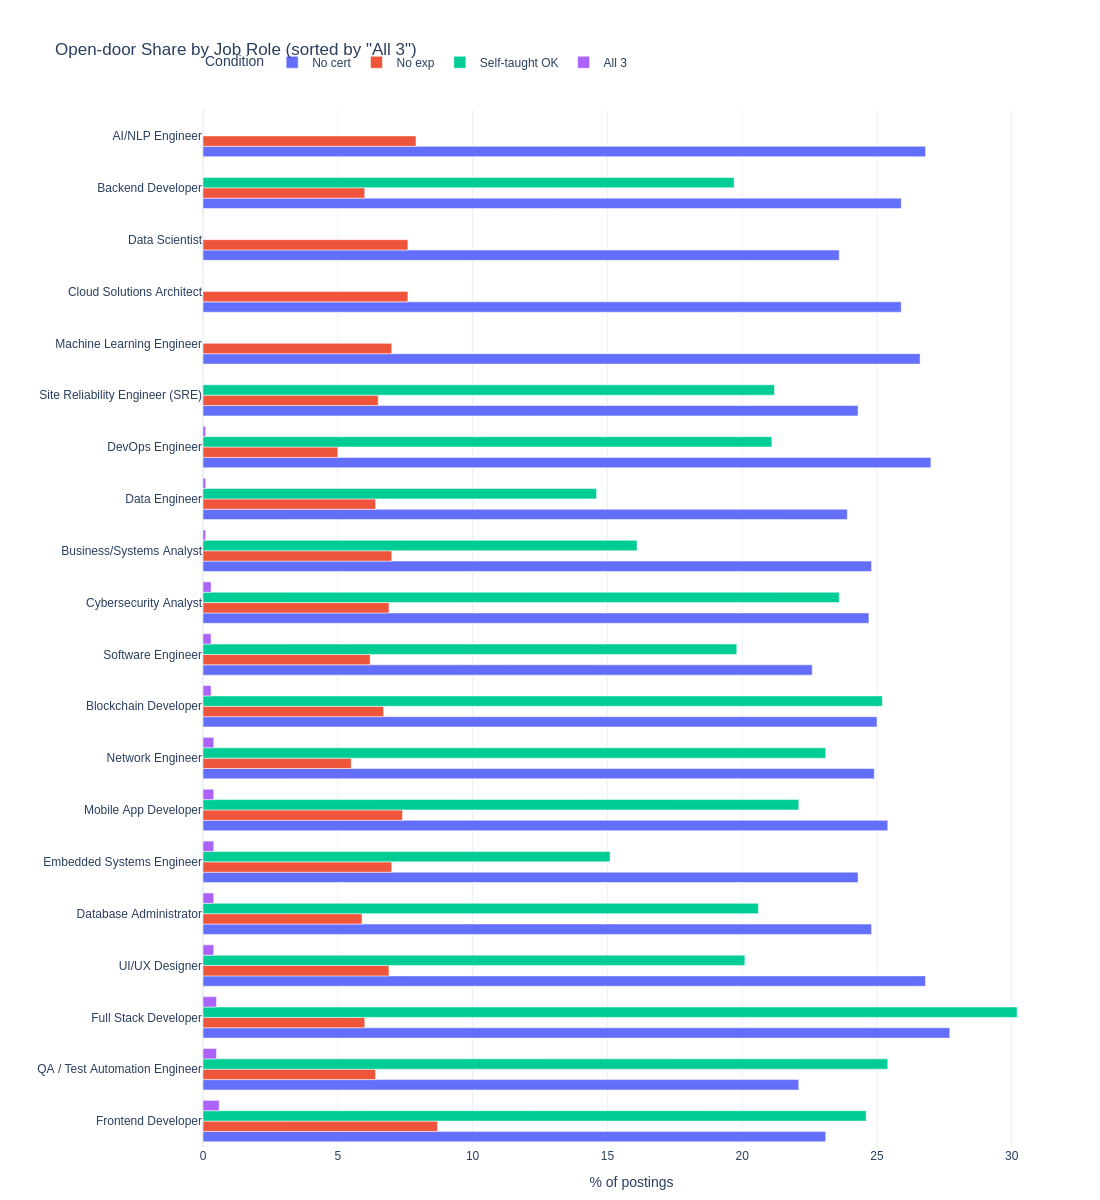

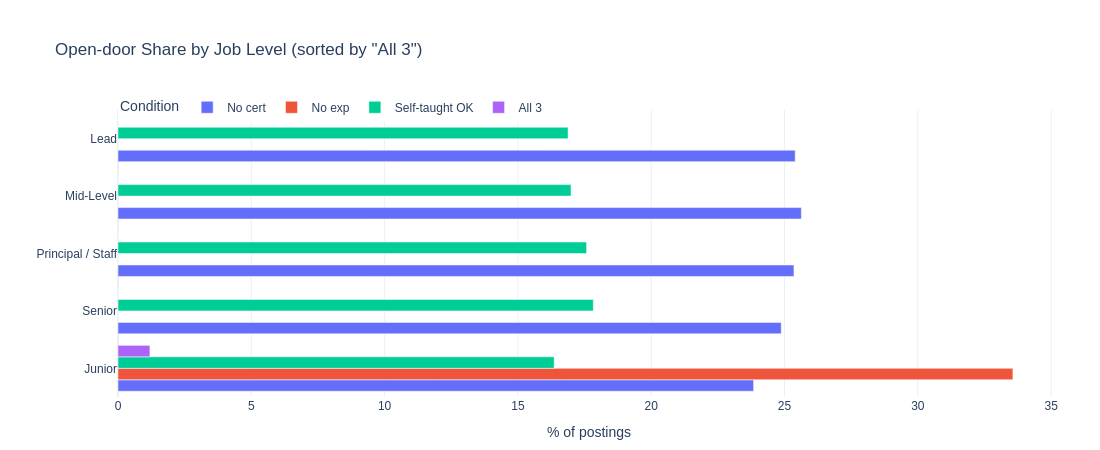

In [22]:
def open_door_by(dim, title, name):
    g = jobs.groupby(dim).agg(Jobs=('Flags', 'size'), **{txt: (col, 'mean') for col, txt in FLAGS.items()})
    g['All 3'] = jobs.assign(x=jobs.Flags == 3).groupby(dim)['x'].mean()
    g = g.sort_values('All 3', ascending=True)
    pct = (g.drop(columns='Jobs') * 100).reset_index().melt(id_vars=dim, var_name='Condition', value_name='Percent')
    pct = pct.merge(g[['Jobs']].reset_index(), on=dim)
    fig = px.bar(pct, x='Percent', y=dim, color='Condition', barmode='group', orientation='h',
                 category_orders={dim: g.index.tolist()}, custom_data=['Jobs'], title=title)
    fig.update_traces(hovertemplate='%{y}<br>%{fullData.name}: %{x:.1f}% (of %{customdata[0]} postings)<extra></extra>')
    fig.update_layout(template='plotly_white', xaxis_title='% of postings', yaxis_title='',
                      height=max(450, 100 + 55 * len(g)), legend=dict(orientation='h', y=1.06, x=0),
                      margin=dict(t=110, b=40, l=40, r=40))
    show_fig(fig, name)

open_door_by('Job Role', 'Open-door Share by Job Role (sorted by "All 3")', 'open_door_by_role')
open_door_by('Job Level', 'Open-door Share by Job Level (sorted by "All 3")', 'open_door_by_level')

### 8.5 Filter the actual jobs
Static mode prints the unfiltered result (top 25 rows); interactive mode adds dropdown filters.

In [23]:
ANY = 'Any'
FILTER_OPTIONS = [ANY, 'Yes (not required / accepted)', 'No (required / not accepted)']

def render_matches(cert=ANY, exp=ANY, self_taught=ANY, role=ANY, n_rows=25):
    s = jobs
    for val, col in [(cert, 'No_Cert'), (exp, 'No_Exp'), (self_taught, 'Self_Taught')]:
        if val.startswith('Yes'):
            s = s[s[col]]
        elif val.startswith('No'):
            s = s[~s[col]]
    if role != ANY:
        s = s[s['Job Role'] == role]
    print(f'Matching postings: {len(s):,}\n')
    if s.empty:
        return
    print('Count by Job Role x Job Level:')
    display(s.groupby(['Job Role', 'Job Level']).size().unstack(fill_value=0))
    show_cols = [col for col in ['Job Role', 'Job Level', EXP, CERT, EDU, SAL, 'Company Name', 'City', 'Country', 'Date Posted']
                 if col in s.columns]
    print(f'\nSample postings (top {n_rows}):')
    display(s[show_cols].head(n_rows))

if STATIC_MODE:
    render_matches()
else:
    w_cert = widgets.Dropdown(options=FILTER_OPTIONS, description='No cert:', layout=widgets.Layout(width='380px'))
    w_exp = widgets.Dropdown(options=FILTER_OPTIONS, description='No exp:', layout=widgets.Layout(width='380px'))
    w_self = widgets.Dropdown(options=FILTER_OPTIONS, description='Self-taught:', layout=widgets.Layout(width='380px'))
    w_role_f = widgets.Dropdown(options=[ANY] + sorted(jobs['Job Role'].unique()), description='Job Role:',
                                layout=widgets.Layout(width='380px'))
    w_n = widgets.Dropdown(options=[10, 25, 50, 100], value=25, description='Rows:', layout=widgets.Layout(width='200px'))
    out_jobs = widgets.Output()

    def refresh_matches(_=None):
        with out_jobs:
            out_jobs.clear_output(wait=True)
            render_matches(w_cert.value, w_exp.value, w_self.value, w_role_f.value, w_n.value)

    for w in (w_cert, w_exp, w_self, w_role_f, w_n):
        w.observe(refresh_matches, names='value')
    display(widgets.VBox([widgets.HBox([w_cert, w_exp]), widgets.HBox([w_self, w_role_f]), w_n]), out_jobs)
    refresh_matches()

Matching postings: 20,000

Count by Job Role x Job Level:


Job Level,Junior,Lead,Mid-Level,Principal / Staff,Senior
Job Role,,,,,
AI/NLP Engineer,211,157,265,109,258
Backend Developer,202,134,290,101,273
Blockchain Developer,196,165,268,108,263
Business/Systems Analyst,172,159,291,107,271
Cloud Solutions Architect,221,148,268,95,268
Cybersecurity Analyst,202,159,282,85,272
Data Engineer,203,151,280,106,260
Data Scientist,225,152,281,98,244
Database Administrator,196,154,292,99,259



Sample postings (top 25):


,Job Role,Job Level,Experience (Years),Certifications,Education,Salary (USD/Year),Company Name,City,Country,Date Posted
0,Data Scientist,Junior,1,Coursera ML Specialization (Andrew Ng),M.Sc. Artificial Intelligence,74000,Uber,New York,USA,2024-10-23
1,DevOps Engineer,Senior,6,HashiCorp Certified: Terraform Associate | Doc...,B.Eng. Software Engineering,144000,Palantir,New York,USA,2025-02-06
2,UI/UX Designer,Principal / Staff,17,Certified Usability Analyst,Bootcamp + Self-Taught,277500,N26,Austin,USA,2024-01-23
3,AI/NLP Engineer,Mid-Level,4,NaN,Ph.D. Artificial Intelligence,135000,Zoom,Cape Town,South Africa,2024-12-01
4,Data Scientist,Mid-Level,5,Coursera ML Specialization (Andrew Ng) | AWS C...,M.Sc. Artificial Intelligence,97000,Supabase,Dublin,Ireland,2025-03-27
5,QA / Test Automation Engineer,Junior,0,Postman API Fundamentals Certification,Bootcamp + Self-Taught,46500,Atlassian,Munich,Germany,2025-05-12
6,UI/UX Designer,Lead,12,Nielsen Norman Group UX Certification,B.A. Visual Communication,143000,Coinbase,Seoul,South Korea,2025-01-10
7,Full Stack Developer,Principal / Staff,17,freeCodeCamp Full Stack Certification,B.Sc. Information Technology,256500,Shopify,Munich,Germany,2024-02-03
8,UI/UX Designer,Junior,0,Interaction Design Foundation Certificate,B.Sc. Human-Computer Interaction,51500,Uber,Paris,France,2025-01-02
9,AI/NLP Engineer,Principal / Staff,20,HuggingFace NLP Course,M.Sc. Computational Linguistics,341500,Robinhood,Delhi,India,2025-02-28


## 9. Do certifications / education / self-taught / no-experience affect salary?
### 9.1 Prepare data

In [24]:
model_df = clean[['Job Role', 'Job Level', EXP, CERT, CNT, EDU, SAL]].copy()
model_df[SAL] = pd.to_numeric(model_df[SAL], errors='coerce')
model_df[EXP] = pd.to_numeric(model_df[EXP], errors='coerce')
model_df[CNT] = pd.to_numeric(model_df[CNT], errors='coerce')
model_df = model_df.dropna(subset=[EXP, SAL, 'Job Role', 'Job Level', EDU])
model_df = model_df[model_df[SAL] > 0].copy()
for col_name in ['Job Role', 'Job Level', EDU]:
    model_df[col_name] = model_df[col_name].astype(str).str.strip()

LEVELS = order_levels(model_df['Job Level'].unique())

model_df['No_Cert'] = no_cert(model_df[CERT])
model_df['No_Exp'] = model_df[EXP] == 0
model_df['Self_Taught'] = model_df[EDU].str.lower() == SELF.lower()
model_df['Has_Cert'] = (~model_df['No_Cert']).astype(int)
model_df['Has_Exp'] = (~model_df['No_Exp']).astype(int)
model_df['SelfTaught'] = model_df['Self_Taught'].astype(int)
model_df['log_sal'] = np.log(model_df[SAL])

print(f'Rows used: {len(model_df):,}')
print('Check - Certifications Count when Certifications is empty:')
print(model_df.groupby('No_Cert')[CNT].describe()[['count', 'mean', 'min', 'max']].round(2))

FACTORS = {'No cert': 'No_Cert', 'No experience': 'No_Exp', 'Self-taught / Bootcamp': 'Self_Taught'}

Rows used: 20,000
Check - Certifications Count when Certifications is empty:
           count  mean  min  max
No_Cert                         
False    14998.0  1.91  1.0  4.0
True      5002.0  0.00  0.0  0.0


### 9.2 RAW comparison (not controlled, can be misleading)

,Factor,n (yes),n (no),Mean yes ($),Mean no ($),Diff (%),Cohen's d,p-value
0,No cert,5002,14998,138973.511,137390.419,1.152,0.023,0.129
1,No experience,1346,18654,60516.345,143361.853,-57.788,-1.676,0.000
2,Self-taught / Bootcamp,3425,16575,135061.752,138349.351,-2.376,-0.048,0.030


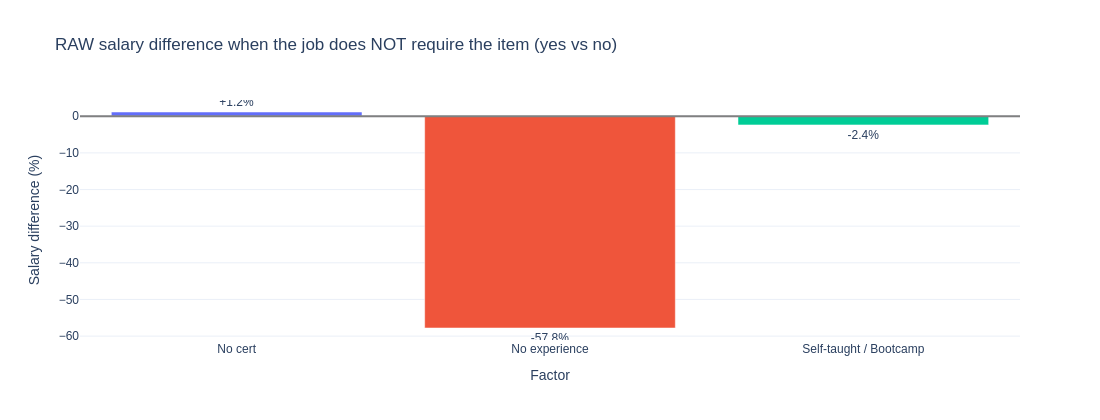

In [25]:
rows = []
for name, col in FACTORS.items():
    x, y = model_df.loc[model_df[col], SAL], model_df.loc[~model_df[col], SAL]
    _, p = stats.mannwhitneyu(x, y, alternative='two-sided')
    pooled = np.sqrt((x.var() + y.var()) / 2)
    rows.append({'Factor': name, 'n (yes)': len(x), 'n (no)': len(y),
                 'Mean yes ($)': x.mean(), 'Mean no ($)': y.mean(),
                 'Diff (%)': (x.mean() / y.mean() - 1) * 100,
                 "Cohen's d": (x.mean() - y.mean()) / pooled, 'p-value': p})
raw = pd.DataFrame(rows).round(3)
display(raw)

fig = px.bar(raw, x='Factor', y='Diff (%)', text=raw['Diff (%)'].map('{:+.1f}%'.format),
             color='Factor', title='RAW salary difference when the job does NOT require the item (yes vs no)')
fig.update_traces(textposition='outside')
fig.add_hline(y=0, line_color='gray')
fig.update_layout(template='plotly_white', showlegend=False, height=420, yaxis_title='Salary difference (%)')
show_fig(fig, 'effect_raw_difference')

### 9.3 Why raw can mislead: who are these jobs?

In [26]:
mix = pd.DataFrame({
    name: model_df.groupby(col).apply(lambda g: pd.Series({
        'Avg experience (yrs)': g[EXP].mean(),
        '% Junior': (g['Job Level'] == LEVELS[0]).mean() * 100}), include_groups=False).loc[True]
    for name, col in FACTORS.items()}).T.round(2)
print('Profile of jobs that do NOT require each item:')
display(mix)

Profile of jobs that do NOT require each item:


,Avg experience (yrs),% Junior
No cert,6.73,19.11
No experience,0.00,100.00
Self-taught / Bootcamp,6.74,19.15


### 9.4 Within the SAME job level

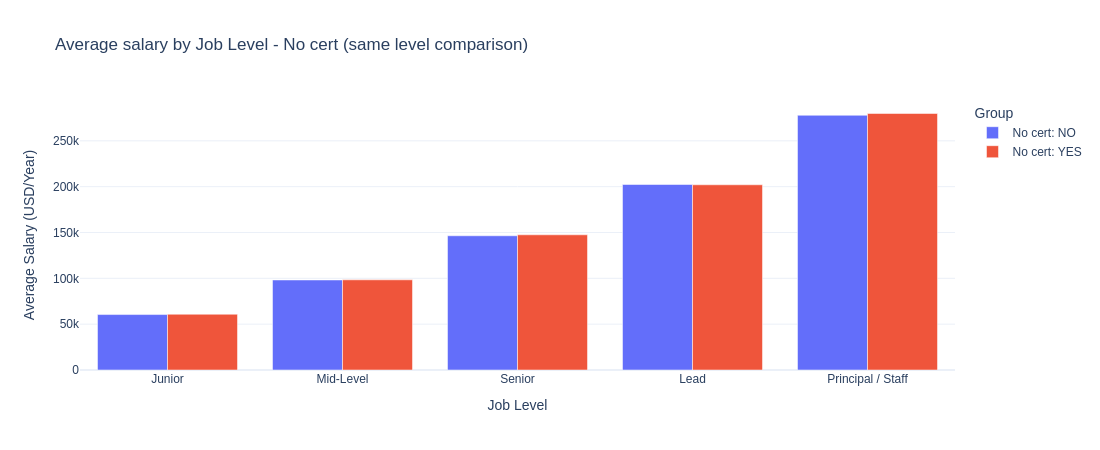

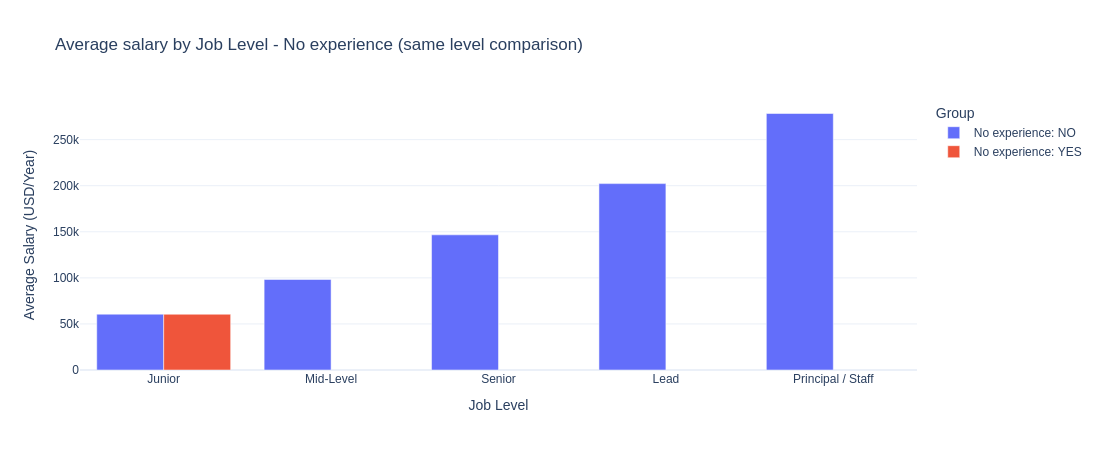

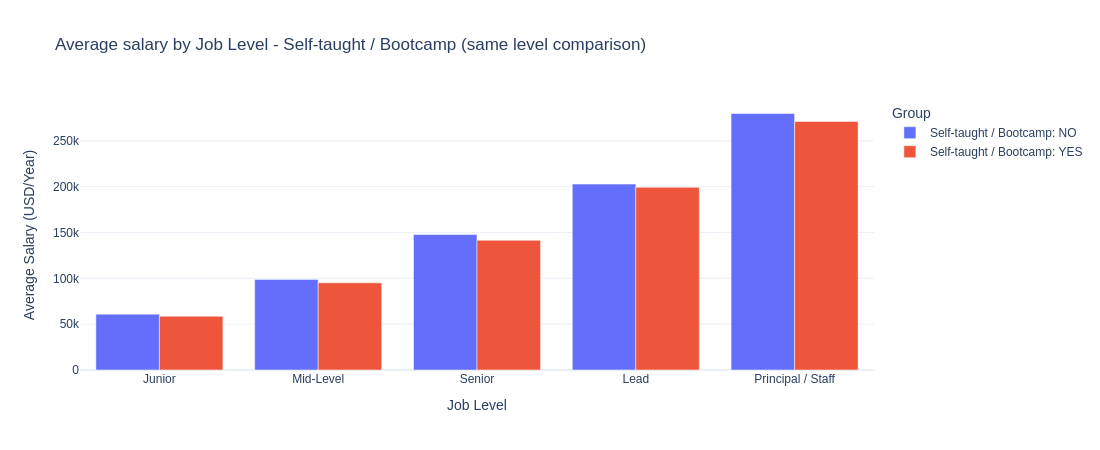

In [27]:
for name, col in FACTORS.items():
    g = model_df.groupby(['Job Level', col])[SAL].agg(['mean', 'count']).reset_index()
    g['Group'] = np.where(g[col], f'{name}: YES', f'{name}: NO')
    fig = px.bar(g, x='Job Level', y='mean', color='Group', barmode='group', custom_data=['count'],
                 category_orders={'Job Level': LEVELS},
                 title=f'Average salary by Job Level - {name} (same level comparison)')
    fig.update_traces(hovertemplate='%{x}<br>%{fullData.name}<br>Avg: $%{y:,.0f}<br>Jobs: %{customdata[0]}<extra></extra>')
    fig.update_layout(template='plotly_white', height=450, yaxis_title='Average Salary (USD/Year)')
    show_fig(fig, 'effect_same_level_' + col.lower())

### 9.5 Controlled regression (log salary, coefficients read as % effect)

,Model,Factor,Effect (%),CI low (%),CI high (%),p-value,Significant
0,M1 No controls,Has certification,-0.348,-1.841,1.168,0.651,False
1,M1 No controls,Requires experience (>0 yrs),114.953,112.402,117.535,0.000,True
2,M1 No controls,Self-taught / Bootcamp,-2.764,-4.425,-1.074,0.001,True
3,M2 + Level + Role,Has certification,-0.106,-0.529,0.318,0.623,False
4,M2 + Level + Role,Requires experience (>0 yrs),0.117,-0.856,1.100,0.814,False
5,M2 + Level + Role,Self-taught / Bootcamp,0.090,-0.413,0.595,0.727,False
6,M3 + Level + Role + Experience (yrs),Has certification,-0.105,-0.527,0.320,0.629,False
7,M3 + Level + Role + Experience (yrs),Requires experience (>0 yrs),0.471,-0.531,1.484,0.358,False
8,M3 + Level + Role + Experience (yrs),Self-taught / Bootcamp,0.084,-0.418,0.590,0.743,False


{'M1 No controls': np.float64(0.143), 'M2 + Level + Role': np.float64(0.932), 'M3 + Level + Role + Experience (yrs)': np.float64(0.932)} <- R²


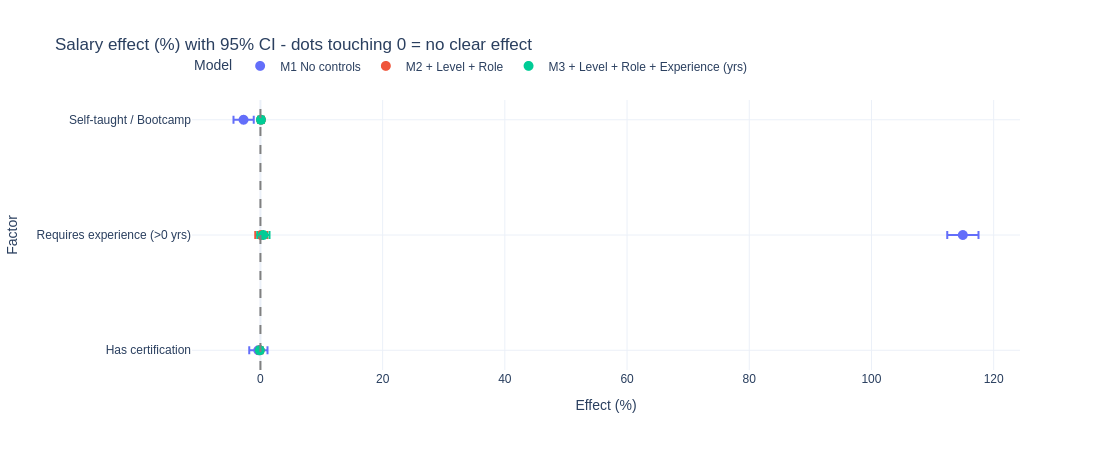

In [28]:
reg_df = model_df.rename(columns={'Job Role': 'Role', 'Job Level': 'Level', EXP: 'Exp', CNT: 'CertCount'})
terms = {'Has_Cert': 'Has certification', 'Has_Exp': 'Requires experience (>0 yrs)',
         'SelfTaught': 'Self-taught / Bootcamp'}
f_base = 'log_sal ~ Has_Cert + Has_Exp + SelfTaught'
models = {
    'M1 No controls': smf.ols(f_base, reg_df).fit(cov_type='HC3'),
    'M2 + Level + Role': smf.ols(f_base + ' + C(Level) + C(Role)', reg_df).fit(cov_type='HC3'),
    'M3 + Level + Role + Experience (yrs)': smf.ols(f_base + ' + C(Level) + C(Role) + Exp', reg_df).fit(cov_type='HC3'),
}

def tidy(model, mname, tmap):
    ci = model.conf_int()
    out = []
    for v, label_ in tmap.items():
        e, lo, hi = [(np.exp(z) - 1) * 100 for z in (model.params[v], ci.loc[v, 0], ci.loc[v, 1])]
        out.append({'Model': mname, 'Factor': label_, 'Effect (%)': e, 'CI low (%)': lo,
                    'CI high (%)': hi, 'p-value': model.pvalues[v],
                    'plus': hi - e, 'minus': e - lo})
    return out

eff = pd.DataFrame([row for m, mod in models.items() for row in tidy(mod, m, terms)])
eff['Significant'] = eff['p-value'] < 0.05
display(eff.drop(columns=['plus', 'minus']).round(3))
print({k: round(m.rsquared, 3) for k, m in models.items()}, '<- R²')

fig = px.scatter(eff, x='Effect (%)', y='Factor', color='Model', error_x='plus', error_x_minus='minus',
                 title='Salary effect (%) with 95% CI - dots touching 0 = no clear effect')
fig.add_vline(x=0, line_dash='dash', line_color='gray')
fig.update_traces(marker=dict(size=10))
fig.update_layout(template='plotly_white', height=450, legend=dict(orientation='h', y=1.18, x=0))
show_fig(fig, 'effect_regression_ci')

### 9.6 Education (every value) + number of certifications

Education effect on salary, SAME level/role/experience, reference group = "Bootcamp + Self-Taught":


,Factor,Effect (%),CI low (%),CI high (%),p-value
0,B.Sc. Computer Science,-0.059,-0.734,0.621,0.865
1,B.Sc. Information Technology,-0.070,-0.832,0.697,0.857
2,B.Eng. Software Engineering,0.251,-0.638,1.149,0.581
3,B.Eng. Electronics & Communication,-0.220,-1.358,0.930,0.706
4,M.Sc. Artificial Intelligence,0.851,-0.590,2.313,0.248
5,B.Sc. Software Engineering,0.385,-0.894,1.679,0.557
6,Ph.D. Artificial Intelligence,1.207,-0.184,2.617,0.089
7,M.Sc. Computer Science,0.343,-0.875,1.576,0.582
8,M.Sc. Data Science,1.703,0.265,3.162,0.020
9,Associate Degree in Computer Science,-0.661,-1.947,0.641,0.318


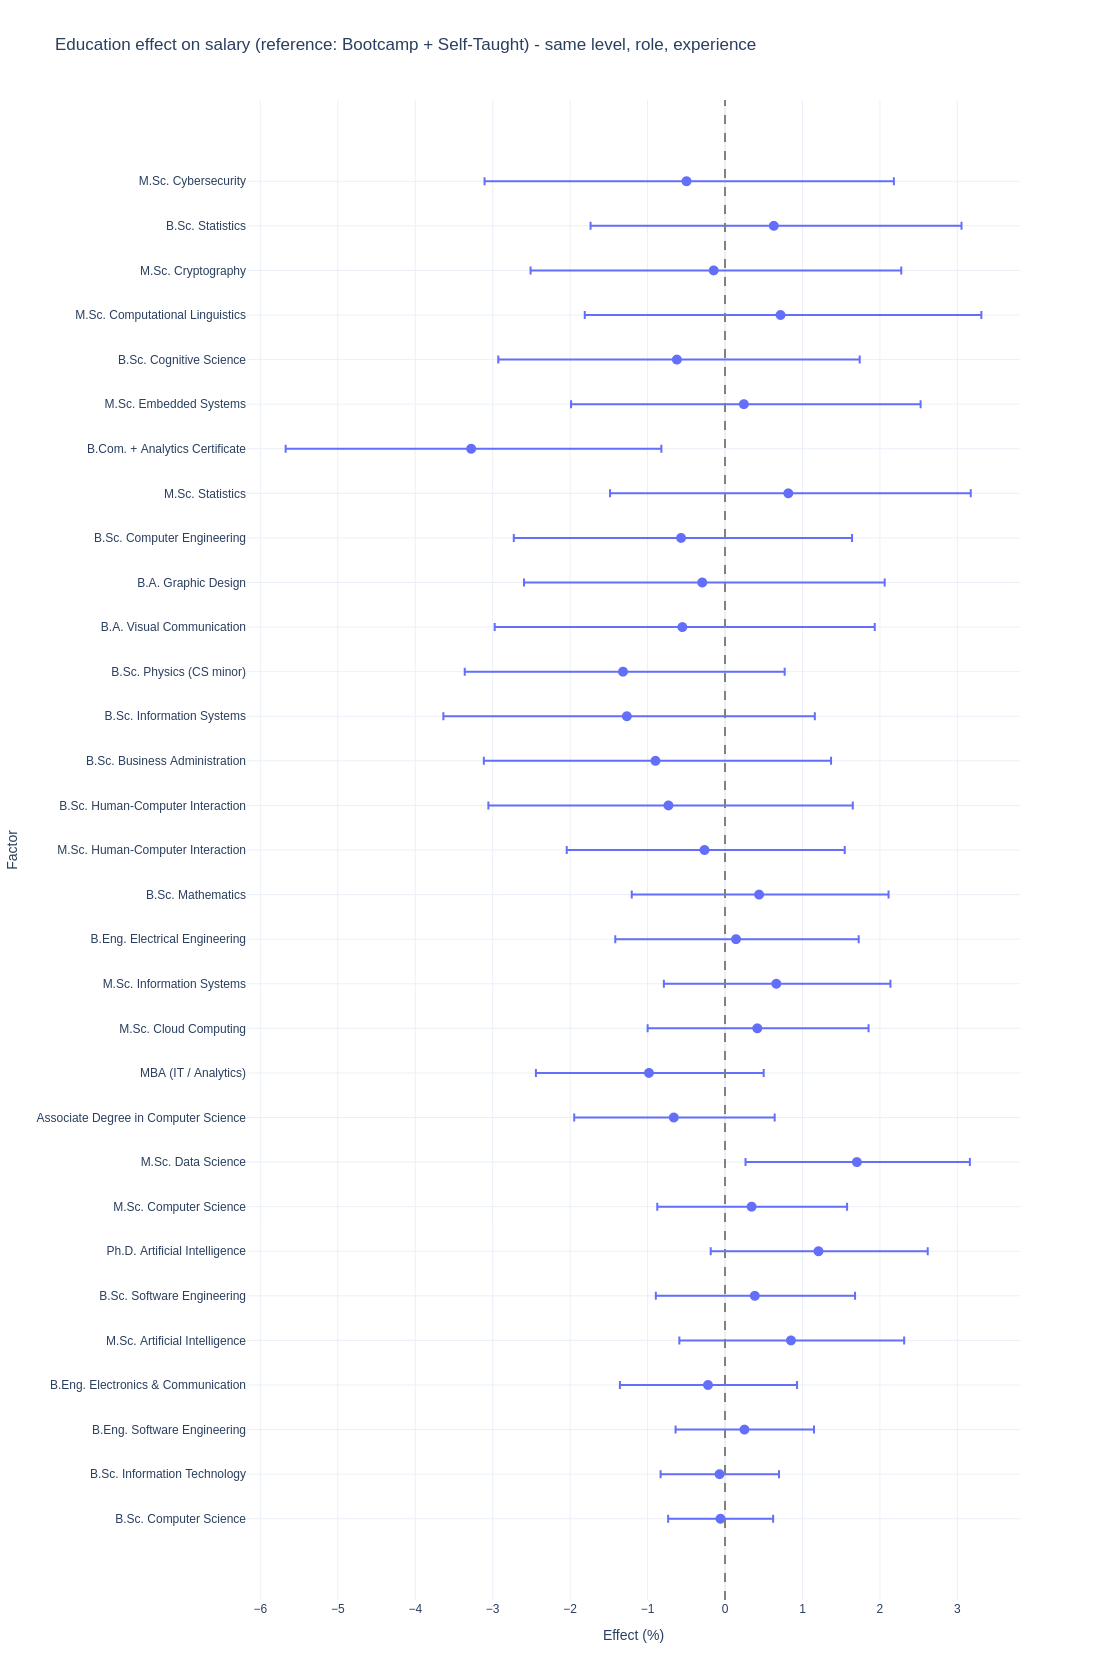


Each extra certification (same level/role/experience): -0.09% salary, p = 0.2453


In [29]:
edu_vals = reg_df[EDU].value_counts().index.tolist()          # most common first = reference group
code_map = {v: f'E{i}' for i, v in enumerate(edu_vals)}
reg_df['EduCode'] = reg_df[EDU].map(code_map)
m_edu = smf.ols("log_sal ~ C(EduCode, Treatment(reference='E0')) + C(Level) + C(Role) + Exp",
                reg_df).fit(cov_type='HC3')
edu_terms = {f"C(EduCode, Treatment(reference='E0'))[T.{code_}]": f'{v}'
             for v, code_ in code_map.items() if code_ != 'E0'}
edu_eff = pd.DataFrame(tidy(m_edu, f'vs "{edu_vals[0]}"', edu_terms))

print(f'Education effect on salary, SAME level/role/experience, reference group = "{edu_vals[0]}":')
display(edu_eff.drop(columns=['plus', 'minus', 'Model']).round(3))

fig = px.scatter(edu_eff, x='Effect (%)', y='Factor', error_x='plus', error_x_minus='minus',
                 title=f'Education effect on salary (reference: {edu_vals[0]}) - same level, role, experience')
fig.add_vline(x=0, line_dash='dash', line_color='gray')
fig.update_traces(marker=dict(size=10))
fig.update_layout(template='plotly_white', height=max(350, 130 + 50 * len(edu_eff)))
show_fig(fig, 'effect_education')

m_cnt = smf.ols('log_sal ~ CertCount + C(Level) + C(Role) + Exp', reg_df).fit(cov_type='HC3')
e_cnt = (np.exp(m_cnt.params['CertCount']) - 1) * 100
print(f"\nEach extra certification (same level/role/experience): {e_cnt:+.2f}% salary, "
      f"p = {m_cnt.pvalues['CertCount']:.4f}")

### 9.7 Conclusion (model M3: same level, role and experience)

In [30]:
for _, row in eff[eff['Model'].str.startswith('M3')].iterrows():
    crosses0 = row['CI low (%)'] <= 0 <= row['CI high (%)']
    if row['p-value'] >= 0.05 or crosses0:
        verdict = 'NO clear effect on salary'
    elif abs(row['Effect (%)']) < 1:
        verdict = f"statistically significant but tiny ({row['Effect (%)']:+.2f}%)"
    else:
        verdict = f"{'higher' if row['Effect (%)'] > 0 else 'lower'} salary by {abs(row['Effect (%)']):.1f}%"
    print(f"- {row['Factor']}: {verdict} (p={row['p-value']:.3f})")

- Has certification: NO clear effect on salary (p=0.629)
- Requires experience (>0 yrs): NO clear effect on salary (p=0.358)
- Self-taught / Bootcamp: NO clear effect on salary (p=0.743)


## 10. Export check
Interactive HTML copies of every chart (dropdowns included) are in `charts/`. Commit that folder next to the notebook.

In [31]:
saved = sorted(os.listdir(CHART_DIR))
print(f'{len(saved)} interactive charts saved in ./{CHART_DIR}/')
for f in saved:
    print(' -', f)

21 interactive charts saved in ./charts/
 - drivers_correlation_heatmap.html
 - drivers_experience_vs_salary.html
 - drivers_salary_by_level.html
 - drivers_variance_explained.html
 - effect_education.html
 - effect_raw_difference.html
 - effect_regression_ci.html
 - effect_same_level_no_cert.html
 - effect_same_level_no_exp.html
 - effect_same_level_self_taught.html
 - job_vacancies_all_jobs.html
 - open_door_by_level.html
 - open_door_by_role.html
 - open_door_combinations.html
 - open_door_summary.html
 - salary_by_domain.html
 - salary_map.html
 - salary_role_level_all_years.html
 - salary_role_level_change.html
 - top_skills_by_role.html
 - top_skills_overall.html
